# Notebook 01 — Importação, Verificação e Exploração do Dataset

"""
╔══════════════════════════════════════════════════════════════════════════════╗
║                    GLOSSÁRIO DO NOTEBOOK 01 + 02                             ║
║        Análise dos Sinais de PPG Utilizando Inteligência Artificial          ║
╚══════════════════════════════════════════════════════════════════════════════╝

Organizado por:
  1. Bibliotecas importadas
  2. Variáveis principais
  3. Funções definidas
  4. Features extraídas (43 total)
  5. Siglas e termos técnicos

═══════════════════════════════════════════════════════════════════════════════
1. BIBLIOTECAS IMPORTADAS
═══════════════════════════════════════════════════════════════════════════════

┌─────────────────┬──────────────────────────────────────────────────────────┐
│ Biblioteca      │ Para que serve                                           │
├─────────────────┼──────────────────────────────────────────────────────────┤
│ wfdb            │ Lê arquivos do PhysioNet (o banco de dados dos sinais)   │
│ os              │ Navega pelas pastas e arquivos do computador             │
│ re              │ Encontra padrões em textos (ex: extrair idade do header) │
│ numpy (np)      │ Faz contas com vetores e matrizes                        │
│ pandas (pd)     │ Organiza dados em tabelas (DataFrames)                   │
│ matplotlib      │ Cria gráficos e figuras                                  │
│ scipy.signal    │ Processamento de sinais: filtros, detecção de picos      │
│   → butter      │ Cria o filtro Butterworth (define os coeficientes)       │
│   → filtfilt    │ Aplica o filtro para frente e para trás (sem atraso)     │
│   → savgol_filter │ Filtro Savitzky-Golay (suaviza sem distorcer picos)    │
│   → find_peaks  │ Encontra picos em um sinal                               │
│ scipy.stats     │ Funções estatísticas                                     │
│   → skew        │ Calcula a assimetria                                     │
│   → kurtosis    │ Calcula a curtose (se a onda tem picos muito extremos)   │
│ scipy.integrate │ Integração numérica                                      │
│   → simpson     │ Calcula a área sob a curva pela regra de Simpson         │
│ sklearn         │ Biblioteca de aprendizado de máquina                     │
└─────────────────┴──────────────────────────────────────────────────────────┘

═══════════════════════════════════════════════════════════════════════════════
2. VARIÁVEIS PRINCIPAIS
═══════════════════════════════════════════════════════════════════════════════

  ┌── CAMINHOS E CONFIGURAÇÕES ──────────────────────────────────────────────────────┐
  │                                                                                  │
  │ BASE_PATH         → Pasta no computador onde estão os arquivos do dataset        │
  │ all_hea           → Lista com os nomes de todos os 66 registros                  │
  │ approved_records  → Lista dos registros aprovados pelo detector de qualidade     │
  │ fs                → Frequência de amostragem = 500 Hz (500 pontos por segundo)   │
  └──────────────────────────────────────────────────────────────────────────────────┘
  ┌── TABELAS (DataFrames) ─────────────────────────────────────────────────────────┐
  │                                                                                 │
  │ df_inv            → Tabela de inventário: lista todos os registros com          │
  │                     sujeito, condição, canais e frequência                      │
  │ df_demo           → Tabela demográfica: idade, gênero, altura, peso e PA        │
  │                     de cada sujeito (22 linhas, uma por sujeito)                │
  │ df_quality        → Tabela de qualidade: resultado da avaliação de cada         │
  │                     registro (GOOD, ACCEPTABLE ou POOR)                         │
  │ df_all            → TABELA PRINCIPAL: contém TODOS os ciclos cardíacos          │
  │                     com suas 43 features + PA de referência + metadados         │
  │                     (42.305 linhas, uma por ciclo)                              │
  └─────────────────────────────────────────────────────────────────────────────────┘
  ┌── SINAIS (arrays numéricos) ────────────────────────────────────────────────────┐
  │                                                                                 │
  │ ppg_raw           → Sinal PPG bruto (como saiu do sensor, com ruído)            │
  │ ppg_filt          → Sinal PPG filtrado (limpo pelo Butterworth)                 │
  │ ecg_raw           → Sinal ECG bruto (eletrocardiograma, com ruído)              │
  │ ecg_filt          → Sinal ECG filtrado (limpo)                                  │
  │ demo_rec          → Registro de demonstração (s1_sit) usado para exemplos       │
  │ result            → Dicionário com todas as etapas da filtragem do PPG:         │
  │                     result['raw']      = sinal bruto                            │
  │                     result['smoothed'] = após Savitzky-Golay                    │
  │                     result['filtered'] = após Butterworth                       │
  └─────────────────────────────────────────────────────────────────────────────────┘
  ┌── PICOS DETECTADOS ────────────────────────────────────────────────────────────┐
  │                                                                                │ 
  │ peaks_ppg         → Posições (índices) dos picos sistólicos no PPG             │ 
  │                     (cada pico = um batimento cardíaco)                        │ 
  │ peaks_ecg         → Posições dos R-peaks no ECG                                │ 
  │                     (o ponto mais alto do batimento no eletrocardiograma)      │ 
  └────────────────────────────────────────────────────────────────────────────────┘
  ┌── MAPEAMENTO DE PA ───────────────────────────────────────────────────────────┐
  │                                                                               │
  │ bp_expanded       → Dicionário que liga cada (sujeito, condição) aos          │
  │                     valores de PA medidos pelo esfigmomanômetro               │
  │ bp_sys_start      → PA sistólica medida ANTES do registro                     │
  │ bp_sys_end        → PA sistólica medida DEPOIS do registro                    │
  │ bp_sys_mean       → Média entre start e end (o valor que usamos como          │
  │                     referência para treinar o modelo)                         │
  │ bp_dia_start/end/mean → Mesma coisa, mas para PA diastólica                   │ 
  └───────────────────────────────────────────────────────────────────────────────┘
  ┌── COLUNAS DE FEATURES ────────────────────────────────────────────────────────┐
  │                                                                               │
  │ feat_cols          → Lista com os nomes das 43 colunas de features            │
  │                      (usada para separar features dos metadados)              │
  └───────────────────────────────────────────────────────────────────────────────┘
═══════════════════════════════════════════════════════════════════════════════
3. FUNÇÕES DEFINIDAS
═══════════════════════════════════════════════════════════════════════════════

  ┌── NOTEBOOK 01 (Exploração e Qualidade) ───────────────────────────────────────┐
  │                                                                               │
  │ get_channel(registro, nome_canal)                                             │
  │   → Pega um canal específico de um registro pelo NOME (não pelo número)       │
  │     Exemplo: get_channel(rec, 'ecg') retorna o sinal ECG                      │
  │                                                                               │
  │ plot_multichannel(registro)                                                   │
  │   → Plota todos os canais de um registro em subgráficos empilhados            │
  │     Útil para visualizar ECG, PPG e acelerômetro juntos                       │
  │                                                                               │
  │ plot_ppg_zoom(registro, inicio, fim)                                          │
  │   → Mostra um trecho ampliado do sinal PPG (2-3 ciclos)                       │
  │     Para ver a morfologia detalhada do pulso                                  │
  │                                                                               │
  │ find_best_pleth_channel(registro)                                             │
  │   → Testa todos os 6 canais PPG e escolhe o de melhor qualidade               │
  │     Critério: maior SNR (relação sinal-ruído)                                 │
  │                                                                               │
  │ assess_ppg_quality_v2(nome_registro)                                          │
  │   → Avalia a qualidade de um registro PPG                                     │
  │     Verifica: SNR, flatline, spikes, range de amplitude                       │
  │     Retorna: 'GOOD', 'ACCEPTABLE' ou 'POOR'                                   │
  │     v2 = versão corrigida (a v1 reprovava tudo por thresholds errados)        │
  └───────────────────────────────────────────────────────────────────────────────┘
  ┌── NOTEBOOK 02 (Pré-processamento e Features) ─────────────────────────────────┐
  │                                                                               │
  │ preprocess_ppg(sinal_bruto, freq_amostragem)                                  │
  │   → Limpa o sinal PPG em 3 etapas:                                            │
  │     1. Savitzky-Golay: suaviza mantendo a forma dos picos                     │
  │     2. Butterworth 0,5–8 Hz: remove ruído fora da faixa cardíaca              │
  │     3. Normalização: padroniza a escala                                       │
  │     Retorna dicionário com sinal em cada etapa                                │
  │                                                                               │
  │ preprocess_ecg(sinal_bruto, freq_amostragem)                                  │
  │   → Limpa o sinal ECG com filtro passa-banda                                  │
  │     Similar ao PPG, mas com faixa de frequência diferente                     │
  │                                                                               │
  │ detect_systolic_peaks_v2(sinal_ppg_filtrado, freq_amostragem)                 │
  │   → Encontra os picos sistólicos no PPG filtrado                              │
  │     Método: derivada → quadrado → integração → threshold adaptativo           │
  │     Validação: só aceita picos com intervalo de 40-200 bpm                    │
  │     Retorna: posições dos picos + informações extras                          │
  │                                                                               │
  │ detect_ecg_r_peaks(sinal_ecg_filtrado, freq_amostragem)                       │
  │   → Encontra os R-peaks no ECG                                                │
  │     Baseado no algoritmo de Pan-Tompkins (referência clássica)                │
  │     Retorna: posições dos R-peaks                                             │
  │                                                                               │
  │ compute_ptt(picos_ecg, picos_ppg, freq_amostragem)                            │
  │   → Calcula o PTT (tempo coração → dedo) para cada batimento                  │
  │     Para cada R-peak, procura o próximo pico PPG                              │
  │     Descarta se o delay > 0,5 segundo (não é fisiológico)                     │
  │     Retorna: lista de PTTs em segundos                                        │
  │                                                                               │
  │ extract_pulse_features_v2(segmento_ppg, freq_amostragem)                      │
  │   → Extrai as 43 features de UM ciclo cardíaco                                │
  │     Recebe: o trecho do PPG entre dois picos consecutivos                     │
  │     Retorna: dicionário com 43 medidas numéricas                              │
  │     v2 = proteção contra divisão por zero (NaN em vez de erro)                │
  │                                                                               │
  │ process_record_v2(nome_registro, caminho, canal_ppg)                          │
  │   → Processa UM registro COMPLETO do início ao fim                            │
  │     Faz tudo: carrega → filtra → picos → PTT → features                       │
  │     Retorna: lista de dicionários (1 por ciclo cardíaco)                      │
  │     É a função que roda em loop para os 66 registros                          │
  └───────────────────────────────────────────────────────────────────────────────┘
═══════════════════════════════════════════════════════════════════════════════
4. FEATURES EXTRAÍDAS (43 no total)
═══════════════════════════════════════════════════════════════════════════════

  ┌── TEMPORAIS (5 features) ───────────────────────────────────────────────────────┐
  │                                                                                 │
  │ cardiac_period_s          → Duração de 1 batimento completo (em segundos)       │
  │                              Ex: 0,8 s = coração batendo a 75 bpm               │
  │                                                                                 │
  │ heart_rate_bpm            → Frequência cardíaca instantânea (batimentos/min)    │
  │                              Calculada como: 60 / cardiac_period_s              │
  │                                                                                 │
  │ systolic_upstroke_time_s  → Tempo de subida sistólica (em segundos)             │
  │   (abreviação: SUT)         Quanto tempo o pulso leva para subir até o pico     │
  │                              Subida rápida = artérias mais rígidas              │
  │                                                                                 │
  │ diastolic_time_s          → Tempo de relaxamento diastólico (em segundos)       │
  │   (abreviação: DT)          Tempo do pico até o início do próximo pulso         │
  │                                                                                 │
  │ sut_dt_ratio              → Proporção contração/relaxamento = SUT / DT          │
  │                              Indica o "equilíbrio" do formato do pulso          │
  │                              ⚠️ Pode ser NaN quando DT ≈ 0                      │
  └─────────────────────────────────────────────────────────────────────────────────┘
  ┌── LARGURAS DE PULSO (24 features) ──────────────────────────────────────────────┐
  │                                                                                 │
  │ Para cada percentual de altura (10%, 25%, 33%, 50%, 66%, 75%):                  │
  │                                                                                 │
  │ w{XX}_total               → Largura total do pulso nessa altura                 │
  │                              Imagine cortar o pulso horizontalmente:            │
  │                              a largura é a distância entre os dois lados        │
  │                                                                                 │
  │ w{XX}_sys                 → Largura só da parte de SUBIDA (sístole)             │
  │                              Do início do pulso até o pico, nessa altura        │
  │                                                                                 │
  │ w{XX}_dia                 → Largura só da parte de DESCIDA (diástole)           │
  │                              Do pico até o final do pulso, nessa altura         │
  │                                                                                 │
  │ w{XX}_ratio               → Proporção descida/subida = dia / sys                │
  │                              Se > 1: descida mais larga que subida              │
  │                              ⚠️ Pode ser NaN quando sys ≈ 0                    │
  │                                                                                 │
  │ Exemplo: w50_total = largura do pulso na metade da altura                       │
  │          w75_sys  = largura da subida a 75% da altura (perto do pico)           │
  │                                                                                 │
  │ São 6 alturas × 4 medidas = 24 features de largura                              │
  └─────────────────────────────────────────────────────────────────────────────────┘ 
  ┌── AMPLITUDE (4 features) ───────────────────────────────────────────────────────┐
  │                                                                                 │
  │ amplitude                 → Diferença entre o ponto mais alto e mais baixo      │
  │                              do pulso (pico − vale). Relacionada com o          │
  │                              volume de sangue bombeado a cada batimento         │
  │                                                                                 │
  │ peak_value                → Intensidade máxima do pulso (valor absoluto         │
  │                              do pico, sem normalização)                         │
  │                               Feature #1 em importância no modelo!              │
  │                                                                                 │
  │ valley_value              → Intensidade mínima do pulso (valor do vale)         │
  │                                                                                 │
  │ crest_factor              → Quão "pontudo" é o pico = pico / RMS                │
  │                              RMS = raiz da média dos quadrados (potência)       │
  │                              Pico pontudo = crest_factor alto                   │
  └─────────────────────────────────────────────────────────────────────────────────┘ 
  ┌── ESTATÍSTICAS (5 features) ────────────────────────────────────────────────────┐
  │                                                                                 │
  │ variance                  → Variação geral do sinal (quanto ele "balança")      │
  │                              = média dos quadrados dos desvios                  │
  │                                                                                 │
  │ std                       → Desvio padrão = raiz quadrada da variância          │
  │                              Mesma ideia, mas na mesma unidade do sinal         │
  │                                                                                 │
  │ skewness                  → Assimetria da forma de onda                         │
  │                              = 0: simétrica                                     │
  │                              > 0: "cauda" para a direita                        │
  │                              < 0: "cauda" para a esquerda                       │
  │                                                                                 │
  │ kurtosis                  → Presença de valores extremos na onda                │
  │                              > 0: picos mais afiados que o normal               │
  │                              < 0: picos mais achatados que o normal             │
  │                                                                                 │
  │ auc                       → Área total sob o pulso normalizado                  │
  │                              (integral do sinal). Relacionada com o             │
  │                              volume de sangue ao longo do ciclo                 │
  └─────────────────────────────────────────────────────────────────────────────────┘ 
  ┌── PARÂMETROS DE HJORTH (3 features) ────────────────────────────────────────────┐
  │                                                                                 │
  │ hjorth_activity           → Potência do sinal (= variância)                     │
  │                              Quão "forte" é o sinal                             │
  │                                                                                 │
  │ hjorth_mobility           → Velocidade de oscilação do sinal                    │
  │                              = raiz(variância da derivada / variância)          │
  │                              Sinal que oscila rápido = mobility alta            │
  │                                                                                 │
  │ hjorth_complexity         → Complexidade do padrão de oscilação                 │
  │                              = mobility da derivada / mobility original         │
  │                              Padrão variado e imprevisível = complexity alta    │
  └─────────────────────────────────────────────────────────────────────────────────┘
  ┌── PTT — PULSE TRANSIT TIME (2 features) ────────────────────────────────────────┐
  │                                                                                 │
  │ ptt_s                     → Tempo coração → dedo em SEGUNDOS                    │
  │                              Intervalo entre o R-peak (ECG) e o pico (PPG)      │
  │                               Feature #2 em importância no modelo!              │
  │                                                                                 │
  │ ptt_ms                    → Mesmo valor, mas em MILISSEGUNDOS (× 1000)          │
  │                               Feature #3 em importância no modelo!              │
  │                              PTT médio do dataset: 208,9 ± 13,1 ms              │
  │                                                                                 │
  │ ⚠️ 6,7% dos ciclos não têm PTT válido (= NaN)                                   │
  │    Motivo: R-peak não detectado ou delay > 0,5 s                                │
  └─────────────────────────────────────────────────────────────────────────────────┘ 
═══════════════════════════════════════════════════════════════════════════════
5. SIGLAS E TERMOS TÉCNICOS
═══════════════════════════════════════════════════════════════════════════════

  PPG     = Fotopletismografia
  ECG     = Eletrocardiograma
  PA      = Pressão Arterial
  PAS     = Pressão Arterial Sistólica
  PAD     = Pressão Arterial Diastólica
  PTT     = Pulse Transit Time (tempo coração → dedo)
  PWV     = Pulse Wave Velocity (velocidade da onda de pulso)
  FC      = Frequência Cardíaca (batimentos por minuto)
  bpm     = Batimentos Por Minuto
  Hz      = Hertz
  Fs      = Frequência de amostragem (= 500 Hz neste dataset)
  NaN     = Not a Number
  SNR     = Signal-to-Noise Ratio (relação sinal/ruído, quanto maior melhor)
  RF      = Random Forest (modelo de IA com 200 "árvores de decisão")
  LOSO    = Leave-One-Subject-Out (testar em 1 sujeito, treinar com os outros)
  MAE     = Mean Absolute Error (erro absoluto médio, em mmHg)
  RMSE    = Root Mean Square Error (erro quadrático médio, em mmHg)
  R²      = Coeficiente de determinação (1 = perfeito, negativo = ruim)
  OOF     = Out-of-Fold (predição feita quando o sujeito estava no teste)
  BHS     = British Hypertension Society (padrão de qualidade para PA)
  AAMI    = Association for the Advancement of Medical Instrumentation
  AUC     = Area Under Curve
  SUT     = Systolic Upstroke Time (tempo de subida sistólica)
  DT      = Diastolic Time (tempo diastólico)
  RMS     = Root Mean Square (raiz da média dos quadrados)
  PCA     = Principal Component Analysis (análise de componentes principais)
  FNN     = Feedforward Neural Network (rede neural simples)
  CNN 1D  = Convolutional Neural Network 1D (rede neural convolucional)
  MLP     = Multilayer Perceptron (outro nome para rede neural simples)

"""

## 1. Imports e Configuração

In [1]:
import wfdb
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Configuração de plots
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# CAMINHO DO DATASET — AJUSTE SE NECESSÁRIO
BASE_PATH = r"C:\Users\USER B. Godoi\.openclaw\workspace\datasets\PTT_PPG"

if os.path.exists(BASE_PATH):
    print(f"✅ Dataset encontrado em: {BASE_PATH}")
    n_files = len([f for f in os.listdir(BASE_PATH) if f.endswith('.hea')])
    print(f"   Arquivos .hea encontrados: {n_files}")
else:
    print(f"❌ Caminho não encontrado: {BASE_PATH}")
    print("   Ajuste BASE_PATH na célula acima.")

✅ Dataset encontrado em: C:\Users\USER B. Godoi\.openclaw\workspace\datasets\PTT_PPG
   Arquivos .hea encontrados: 66


## 2. Inventário Completo do Dataset
Listar todos os registros, verificar consistência de canais e frequência de amostragem.

In [2]:
# Listar todos os registros
all_hea = sorted([f.replace('.hea', '') for f in os.listdir(BASE_PATH) if f.endswith('.hea')])
print(f"Total de registros: {len(all_hea)}")

# Inventário detalhado
inventory = []
for rec_name in all_hea:
    try:
        header = wfdb.rdheader(os.path.join(BASE_PATH, rec_name))
        # Separar sujeito e condição
        parts = rec_name.split('_', 1)
        subj = parts[0] if len(parts) > 0 else rec_name
        cond = parts[1] if len(parts) > 1 else 'unknown'
        
        inventory.append({
            'record': rec_name,
            'subject': subj,
            'condition': cond,
            'fs': header.fs,
            'n_channels': header.n_sig,
            'channels': header.sig_name,
            'duration_s': round(header.sig_len / header.fs, 1),
            'samples': header.sig_len
        })
    except Exception as e:
        print(f"⚠️ Erro em {rec_name}: {e}")

df_inv = pd.DataFrame(inventory)

# Resumo
print(f"\n{'='*60}")
print(f"RESUMO DO DATASET")
print(f"{'='*60}")
print(f"Registros: {len(df_inv)}")
print(f"Sujeitos únicos: {df_inv['subject'].nunique()}")
print(f"Condições: {sorted(df_inv['condition'].unique())}")
print(f"Fs: {df_inv['fs'].unique()} Hz")
print(f"Canais por registro: {df_inv['n_channels'].unique()}")
print(f"Duração total: {df_inv['duration_s'].sum()/60:.1f} min")
print(f"Duração média por registro: {df_inv['duration_s'].mean():.1f} s")

Total de registros: 66

RESUMO DO DATASET
Registros: 66
Sujeitos únicos: 22
Condições: ['run', 'sit', 'walk']
Fs: [500] Hz
Canais por registro: [18]
Duração total: 540.6 min
Duração média por registro: 491.4 s


In [3]:
# Tabela de registros por sujeito × condição
pivot = df_inv.pivot_table(index='subject', columns='condition', 
                           values='duration_s', aggfunc='first')
print("Duração (s) por sujeito × condição:")
print(pivot.to_string())

Duração (s) por sujeito × condição:
condition    run    sit   walk
subject                       
s1         490.5  508.1  491.8
s10        485.6  485.7  485.7
s11        493.8  487.2  486.5
s12        484.7  485.9  485.8
s13        486.2  487.1  486.9
s14        487.6  496.1  487.7
s15        495.0  484.4  484.6
s16        494.0  488.0  487.3
s17        484.9  485.9  485.1
s18        484.3  484.5  485.3
s19        484.8  499.2  492.5
s2         493.2  492.4  493.7
s20        497.4  495.4  484.5
s21        485.1  489.9  486.4
s22        489.4  485.3  485.3
s3         487.5  492.3  493.2
s4         491.5  493.9  506.4
s5         551.3  494.4  491.7
s6         497.4  499.0  515.4
s7         497.3  506.0  492.0
s8         485.1  489.5  487.3
s9         488.5  486.8  487.5


## 3. Mapeamento dos Canais
Identificar o que cada canal representa. Isso é **crítico** — nunca acessar por índice fixo.

### Canais do dataset PTT PPG (descobertos na execução anterior):
| Canal | Descrição provável |
|-------|-------------------|
| `ecg` | Eletrocardiograma |
| `pleth_1` a `pleth_6` | PPG em diferentes locais/comprimentos de onda |
| `lc_1`, `lc_2` | Load cell (força/pressão mecânica) |
| `temp_1` a `temp_3` | Temperatura |
| `a_x`, `a_y`, `a_z` | Acelerômetro (detecção de movimento) |
| `g_x`, `g_y`, `g_z` | Giroscópio |

### ⚠️ DESCOBERTA CRÍTICA
**O dataset NÃO contém sinal ABP (pressão arterial invasiva) contínuo.**  
A pressão arterial está disponível apenas como metadado no header (`bp_sys_start`, `bp_dia_start`).

Isso significa que:
1. NÃO é possível extrair SBP/DBP batimento-a-batimento de um sinal de referência
2. A abordagem deve ser: **features do PPG → predizer PA medida no início**
3. Ou usar **PTT (ECG + PPG)** para estimar variações relativas de PA

In [4]:
# Verificar canais do primeiro registro
rec = wfdb.rdrecord(os.path.join(BASE_PATH, all_hea[0]))
print(f"Registro: {all_hea[0]}")
print(f"Fs: {rec.fs} Hz")
print(f"\nCanais ({rec.n_sig}):")
for i, (name, unit) in enumerate(zip(rec.sig_name, rec.units)):
    signal = rec.p_signal[:, i]
    print(f"  [{i:2d}] {name:10s} | Unidade: {unit:6s} | "
          f"Min: {signal.min():12.2f} | Max: {signal.max():12.2f} | "
          f"Média: {signal.mean():12.2f} | Std: {signal.std():10.2f}")

Registro: s10_run
Fs: 500 Hz

Canais (18):
  [ 0] ecg        | Unidade: mV     | Min:     14367.00 | Max:     64188.83 | Média:     32629.65 | Std:    5836.95
  [ 1] pleth_1    | Unidade: NU     | Min:     63520.00 | Max:     66192.35 | Média:     64789.56 | Std:     400.08
  [ 2] pleth_2    | Unidade: NU     | Min:     63328.00 | Max:     70417.37 | Média:     66658.84 | Std:    1347.82
  [ 3] pleth_3    | Unidade: NU     | Min:      3067.00 | Max:      3748.87 | Média:      3371.91 | Std:      96.22
  [ 4] pleth_4    | Unidade: NU     | Min:     90281.00 | Max:     91381.73 | Média:     90909.62 | Std:     169.23
  [ 5] pleth_5    | Unidade: NU     | Min:    101463.00 | Max:    104273.33 | Média:    102872.00 | Std:     414.81
  [ 6] pleth_6    | Unidade: NU     | Min:      5323.25 | Max:      6336.78 | Média:      5930.15 | Std:     151.64
  [ 7] lc_1       | Unidade: NU     | Min:   6195648.00 | Max:   6349823.51 | Média:   6288733.40 | Std:   17222.70
  [ 8] lc_2       | Unidade: 

In [5]:
# Verificar TODOS os campos disponíveis nos metadados do header
header = wfdb.rdheader(os.path.join(BASE_PATH, all_hea[0]))
print("Comentários do header (TODOS os campos):")
for line in header.comments:
    print(f"  {line}")

Comentários do header (TODOS os campos):
  <filename>: s10_run <activity>: run <gender>: female <height>: 160 <weight>: 60 <age>: 25 <bp_sys_start>: 113 <bp_sys_end>: 121 <bp_dia_start>: 69 <bp_dia_end>: 74 <hr_1_start>: 73 <hr_2_start>: 75 <hr_1_end>: 93 <hr_2_end>: 90 <spo2_start>: 96 <spo2_end>: 97


## 4. Caracterização Demográfica Completa
Extrair **todos** os campos disponíveis dos headers para análise de viés.

In [6]:
# Extrair metadados de um registro por sujeito (sit)
subjects = sorted(df_inv['subject'].unique())
demographic_data = []

for subj in subjects:
    # Pegar o registro _sit de preferência
    subj_records = df_inv[df_inv['subject'] == subj]['record'].tolist()
    sit_rec = next((r for r in subj_records if '_sit' in r), subj_records[0])
    
    header = wfdb.rdheader(os.path.join(BASE_PATH, sit_rec))
    
    info = {'subject': subj}
    for line in header.comments:
        matches = re.findall(r"<(.*?)>:\s*(.*?)(?=\s*<|$)", line)
        for key, value in matches:
            info[key.strip()] = value.strip()
    
    demographic_data.append(info)

df_demo = pd.DataFrame(demographic_data)

# Converter tipos numéricos
for col in ['age', 'bp_sys_start', 'bp_dia_start', 'height', 'weight']:
    if col in df_demo.columns:
        df_demo[col] = pd.to_numeric(df_demo[col], errors='coerce')

print("Todos os campos extraídos:")
print(df_demo.to_string())
print(f"\nColunas disponíveis: {list(df_demo.columns)}")

Todos os campos extraídos:
   subject filename activity  gender  height  weight  age  bp_sys_start bp_sys_end  bp_dia_start bp_dia_end hr_1_start hr_2_start hr_1_end hr_2_end spo2_start spo2_end
0       s1   s1_sit      sit  female     160      50   25            87         87            59         57         74         69       74       70         98       98
1      s10  s10_sit      sit  female     160      60   25           106         98            69         65         73         72       71       69         95       98
2      s11  s11_sit      sit    male     180      65   30           106        100            73         70         61         60       64       62         97       98
3      s12  s12_sit      sit    male     185      80   25           129        116            80         75         70         76       72       73         95       97
4      s13  s13_sit      sit    male     175      80   25           140        125            84         89         74         78    

In [7]:
print("=" * 60)
print("PERFIL DEMOGRÁFICO — ANÁLISE COMPLETA")
print("=" * 60)

# Gênero
print(f"\n📊 GÊNERO:")
print(df_demo['gender'].value_counts().to_string())
pct_female = (df_demo['gender'].str.lower() == 'female').mean() * 100
print(f"   Proporção feminina: {pct_female:.1f}%")
print(f"   ⚠️ Desbalanceamento: {'SIM' if abs(pct_female - 50) > 15 else 'NÃO'}")

# Idade
print(f"\n📊 IDADE:")
print(f"   Média ± DP: {df_demo['age'].mean():.1f} ± {df_demo['age'].std():.1f} anos")
print(f"   Mediana: {df_demo['age'].median():.0f} anos")
print(f"   Range: {df_demo['age'].min():.0f} — {df_demo['age'].max():.0f} anos")
print(f"   ⚠️ Predominância jovens: {'SIM' if df_demo['age'].median() < 35 else 'NÃO'}")

# Pressão arterial
if 'bp_sys_start' in df_demo.columns:
    print(f"\n📊 PA SISTÓLICA (início):")
    print(f"   Média ± DP: {df_demo['bp_sys_start'].mean():.1f} ± {df_demo['bp_sys_start'].std():.1f} mmHg")
    print(f"   Range: {df_demo['bp_sys_start'].min():.0f} — {df_demo['bp_sys_start'].max():.0f} mmHg")
    
    # Classificação (AHA 2017)
    normal = (df_demo['bp_sys_start'] < 120).sum()
    elevated = ((df_demo['bp_sys_start'] >= 120) & (df_demo['bp_sys_start'] < 130)).sum()
    stage1 = ((df_demo['bp_sys_start'] >= 130) & (df_demo['bp_sys_start'] < 140)).sum()
    stage2 = (df_demo['bp_sys_start'] >= 140).sum()
    n = len(df_demo)
    print(f"   Normal (<120):        {normal} ({normal/n*100:.0f}%)")
    print(f"   Elevada (120-129):    {elevated} ({elevated/n*100:.0f}%)")
    print(f"   Estágio 1 (130-139):  {stage1} ({stage1/n*100:.0f}%)")
    print(f"   Estágio 2 (≥140):     {stage2} ({stage2/n*100:.0f}%)")

if 'bp_dia_start' in df_demo.columns:
    print(f"\n📊 PA DIASTÓLICA (início):")
    print(f"   Média ± DP: {df_demo['bp_dia_start'].mean():.1f} ± {df_demo['bp_dia_start'].std():.1f} mmHg")
    print(f"   Range: {df_demo['bp_dia_start'].min():.0f} — {df_demo['bp_dia_start'].max():.0f} mmHg")

PERFIL DEMOGRÁFICO — ANÁLISE COMPLETA

📊 GÊNERO:
gender
male      15
female     7
   Proporção feminina: 31.8%
   ⚠️ Desbalanceamento: SIM

📊 IDADE:
   Média ± DP: 28.4 ± 9.2 anos
   Mediana: 25 anos
   Range: 20 — 55 anos
   ⚠️ Predominância jovens: SIM

📊 PA SISTÓLICA (início):
   Média ± DP: 119.2 ± 15.1 mmHg
   Range: 87 — 160 mmHg
   Normal (<120):        12 (55%)
   Elevada (120-129):    7 (32%)
   Estágio 1 (130-139):  1 (5%)
   Estágio 2 (≥140):     2 (9%)

📊 PA DIASTÓLICA (início):
   Média ± DP: 75.7 ± 8.3 mmHg
   Range: 55 — 89 mmHg


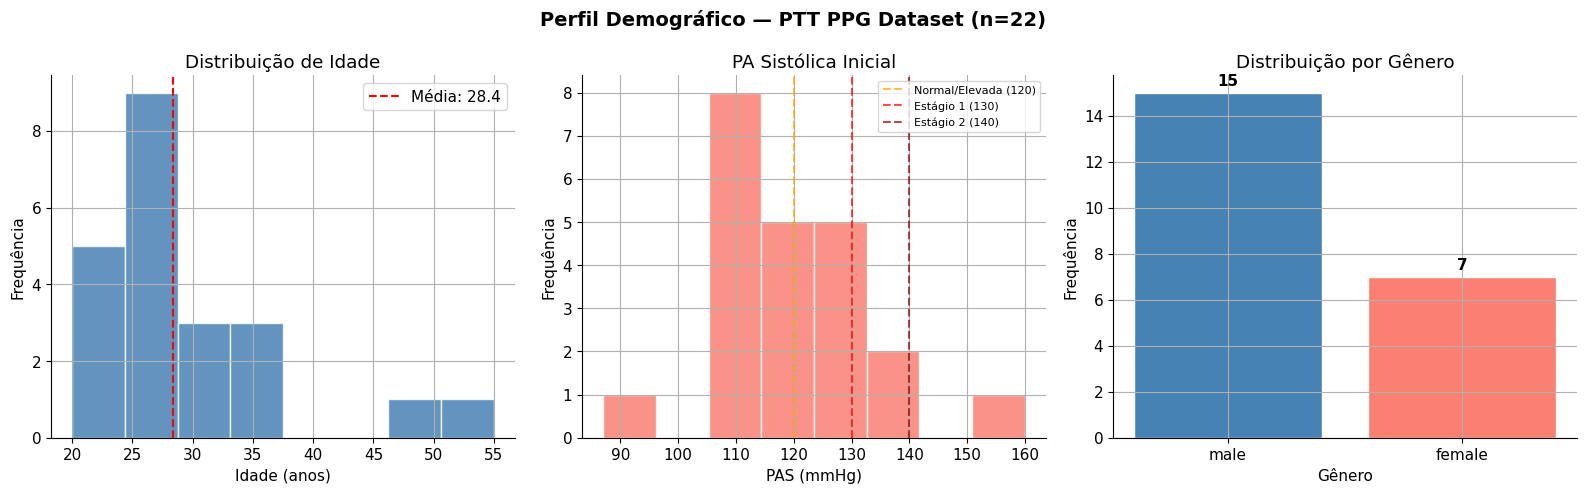

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Perfil Demográfico — PTT PPG Dataset (n=22)', fontsize=14, fontweight='bold')

# Idade
axes[0].hist(df_demo['age'].dropna(), bins=8, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df_demo['age'].mean(), color='red', linestyle='--', 
                label=f"Média: {df_demo['age'].mean():.1f}")
axes[0].set_xlabel('Idade (anos)')
axes[0].set_ylabel('Frequência')
axes[0].set_title('Distribuição de Idade')
axes[0].legend()

# PA Sistólica
axes[1].hist(df_demo['bp_sys_start'].dropna(), bins=8, color='salmon', edgecolor='white', alpha=0.85)
axes[1].axvline(120, color='orange', linestyle='--', alpha=0.7, label='Normal/Elevada (120)')
axes[1].axvline(130, color='red', linestyle='--', alpha=0.7, label='Estágio 1 (130)')
axes[1].axvline(140, color='darkred', linestyle='--', alpha=0.7, label='Estágio 2 (140)')
axes[1].set_xlabel('PAS (mmHg)')
axes[1].set_ylabel('Frequência')
axes[1].set_title('PA Sistólica Inicial')
axes[1].legend(fontsize=8)

# Gênero
gender_counts = df_demo['gender'].value_counts()
colors = ['steelblue' if g.lower() == 'male' else 'salmon' for g in gender_counts.index]
axes[2].bar(gender_counts.index, gender_counts.values, color=colors, edgecolor='white')
axes[2].set_xlabel('Gênero')
axes[2].set_ylabel('Frequência')
axes[2].set_title('Distribuição por Gênero')
for i, v in enumerate(gender_counts.values):
    axes[2].text(i, v + 0.3, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Visualização dos Sinais
Inspecionar visualmente os sinais PPG e ECG para diferentes sujeitos e condições.  
**Regra**: Sempre visualizar ANTES de processar.

In [9]:
def get_channel(record, target_names):
    """Busca canal por nome (case-insensitive). Retorna (índice, sinal) ou (None, None)."""
    for i, name in enumerate(record.sig_name):
        if name.lower() in [t.lower() for t in target_names]:
            return i, record.p_signal[:, i]
    return None, None


def plot_multichannel(record_name, start_s=10, duration_s=10, 
                      channels_to_plot=None):
    """
    Plota múltiplos canais de um registro.
    
    Parameters
    ----------
    record_name : str - Nome do registro (ex: 's1_sit')
    start_s : float - Segundo inicial
    duration_s : float - Duração da janela
    channels_to_plot : list - Nomes dos canais a plotar (None = todos)
    """
    rec = wfdb.rdrecord(os.path.join(BASE_PATH, record_name))
    fs = rec.fs
    
    start = int(start_s * fs)
    end = min(int((start_s + duration_s) * fs), rec.p_signal.shape[0])
    time = np.arange(start, end) / fs
    
    # Filtrar canais se especificado
    if channels_to_plot:
        indices = [i for i, n in enumerate(rec.sig_name) 
                   if n.lower() in [c.lower() for c in channels_to_plot]]
    else:
        indices = list(range(rec.n_sig))
    
    n = len(indices)
    fig, axes = plt.subplots(n, 1, figsize=(16, 2.5 * n), sharex=True)
    if n == 1:
        axes = [axes]
    
    colors = ['tab:blue', 'tab:green', 'tab:red', 'tab:orange', 
              'tab:purple', 'tab:brown', 'tab:cyan']
    
    for ax_i, ch_i in enumerate(indices):
        signal = rec.p_signal[start:end, ch_i]
        ax = axes[ax_i]
        ax.plot(time, signal, color=colors[ax_i % len(colors)], linewidth=0.7)
        ax.set_ylabel(f"{rec.sig_name[ch_i]}\n[{rec.units[ch_i]}]", fontsize=9)
    
    axes[-1].set_xlabel('Tempo (s)')
    fig.suptitle(f'{record_name} | Fs={fs} Hz | {start_s}–{start_s+duration_s}s', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

### 5a. Sinais principais: ECG + PPG (repouso)

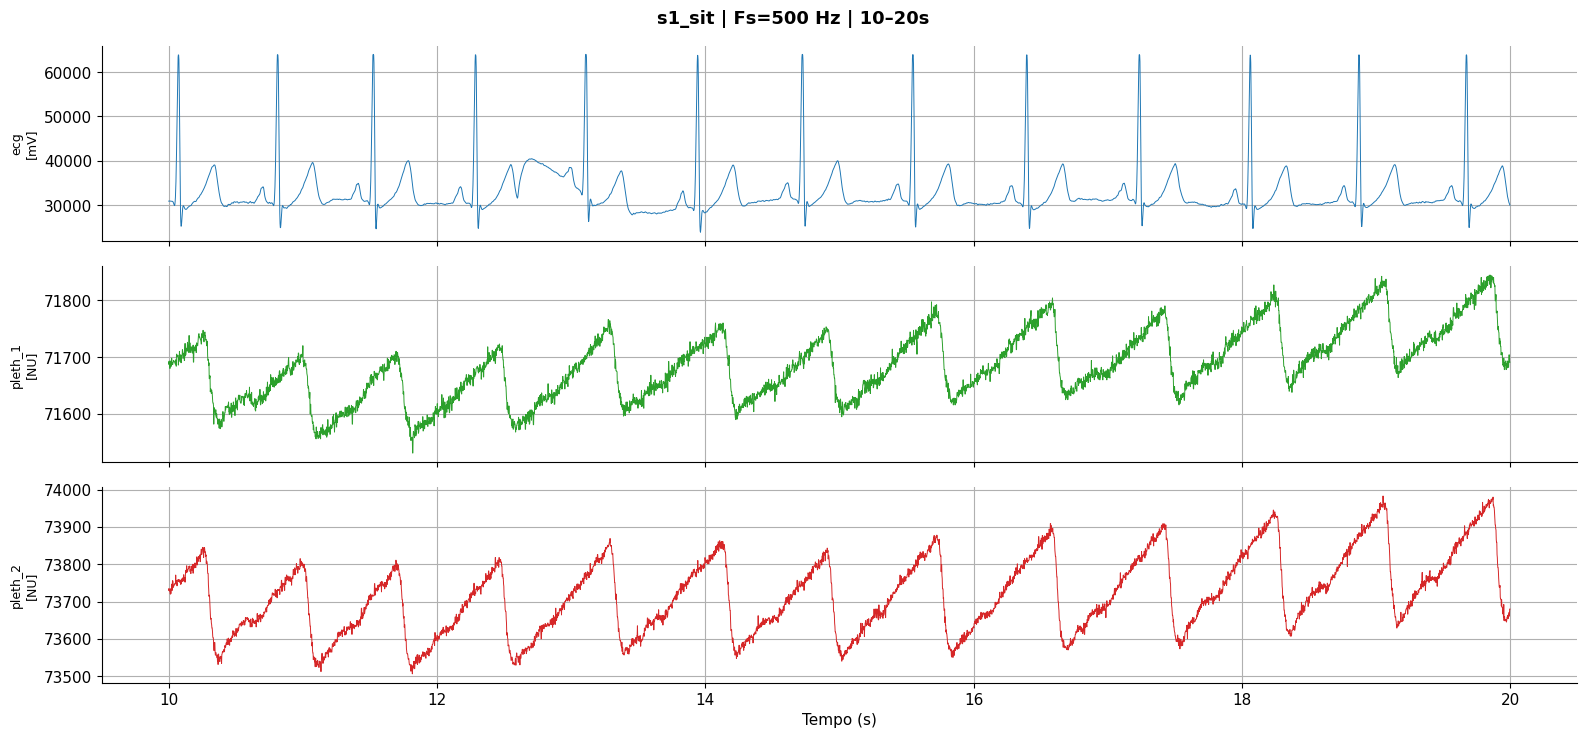

In [10]:
# ECG e PPG do sujeito 1 em repouso
plot_multichannel('s1_sit', start_s=10, duration_s=10, 
                  channels_to_plot=['ecg', 'pleth_1', 'pleth_2'])

### 5b. Mesmo sujeito em movimento — comparar artefatos

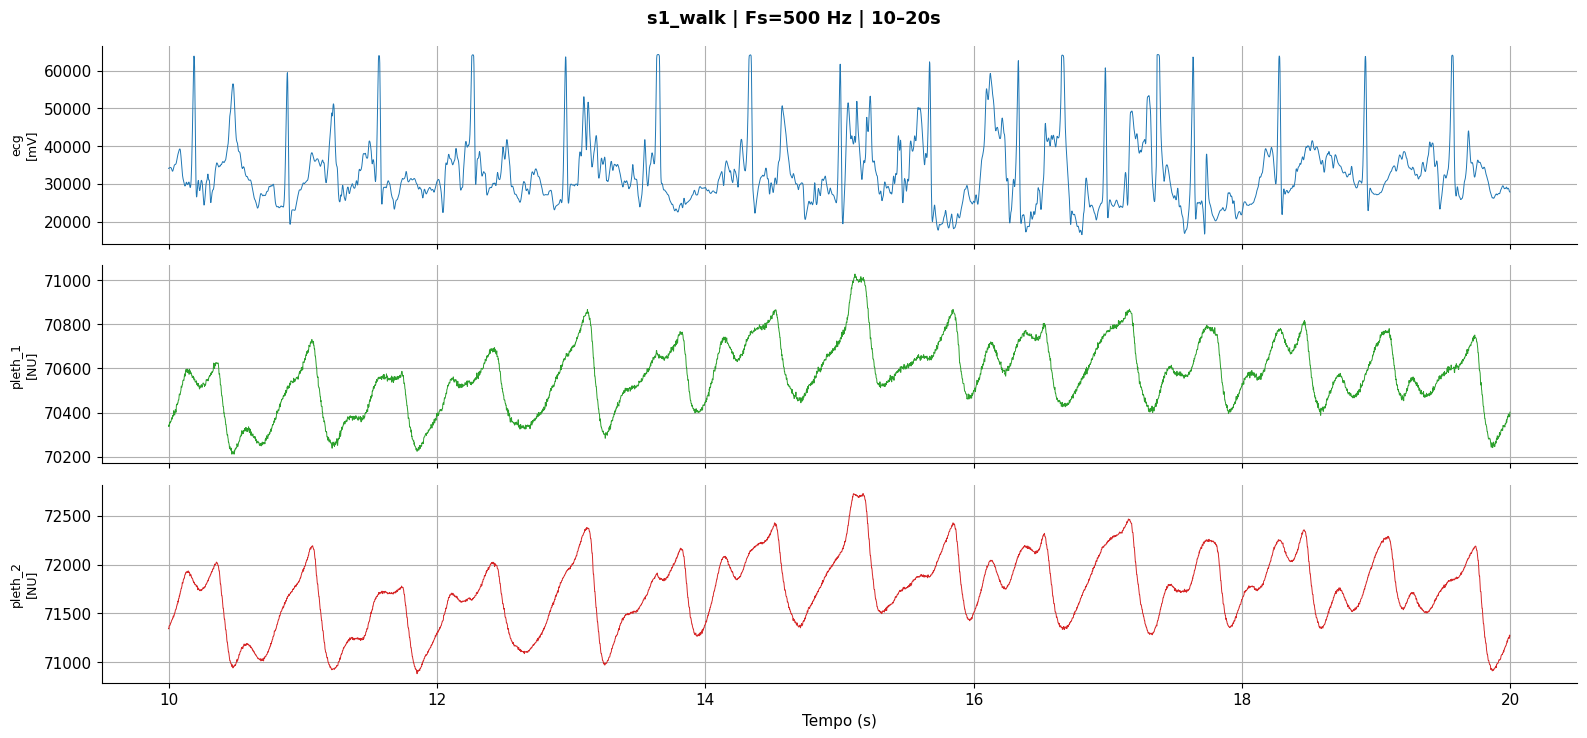

In [11]:
# Mesmo sujeito caminhando — notar diferença na qualidade
plot_multichannel('s1_walk', start_s=10, duration_s=10, 
                  channels_to_plot=['ecg', 'pleth_1', 'pleth_2'])

### 5c. Zoom na morfologia do PPG (2-3 ciclos cardíacos)

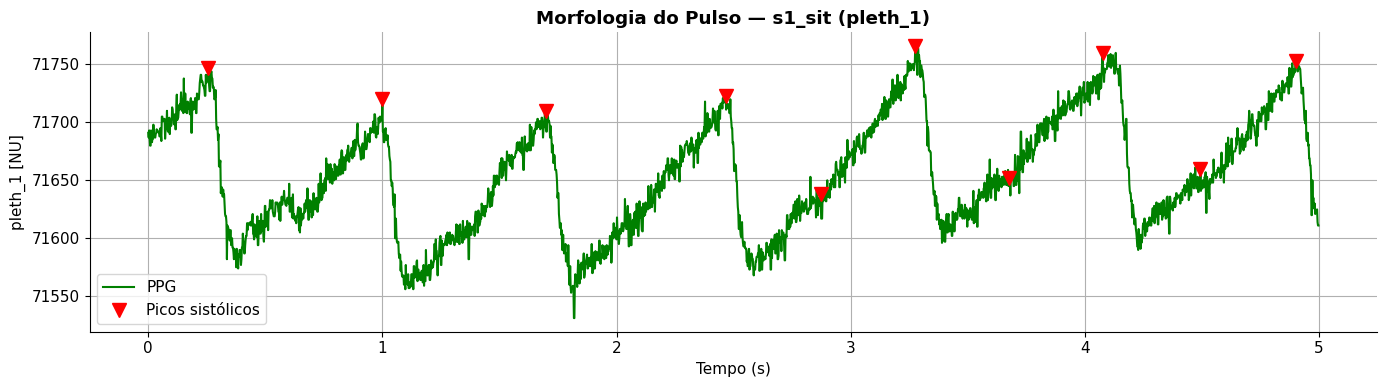

  Picos detectados: 10
  FC estimada: 125.8 ± 31.4 bpm (D7.4 sanity-check)


In [12]:
def plot_ppg_zoom(record_name, pleth_channel='pleth_1', start_s=10, duration_s=3):
    """Zoom no PPG para ver morfologia do pulso e estimar FC."""
    rec = wfdb.rdrecord(os.path.join(BASE_PATH, record_name))
    fs = rec.fs
    
    # Buscar canal por nome
    try:
        ch_idx = rec.sig_name.index(pleth_channel)
    except ValueError:
        print(f"Canal '{pleth_channel}' não encontrado. Disponíveis: {rec.sig_name}")
        return
    
    start = int(start_s * fs)
    end = min(int((start_s + duration_s) * fs), rec.p_signal.shape[0])
    ppg = rec.p_signal[start:end, ch_idx]
    time = np.arange(len(ppg)) / fs
    
    # Detectar picos (D5.2: distância mínima 200ms → 0.4s para ser conservador)
    peaks, _ = find_peaks(ppg, distance=int(0.4 * fs))
    
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(time, ppg, 'g-', linewidth=1.5, label='PPG')
    ax.plot(time[peaks], ppg[peaks], 'rv', markersize=10, label='Picos sistólicos')
    ax.set_xlabel('Tempo (s)')
    ax.set_ylabel(f'{pleth_channel} [{rec.units[ch_idx]}]')
    ax.set_title(f'Morfologia do Pulso — {record_name} ({pleth_channel})', fontweight='bold')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Sanity-check FC (D7.4)
    if len(peaks) > 1:
        intervals = np.diff(peaks) / fs
        valid = (intervals > 0.3) & (intervals < 2.0)
        if valid.sum() > 0:
            hr = 60.0 / intervals[valid]
            print(f"  Picos detectados: {len(peaks)}")
            print(f"  FC estimada: {hr.mean():.1f} ± {hr.std():.1f} bpm (D7.4 sanity-check)")

# Executar
plot_ppg_zoom('s1_sit', 'pleth_1', start_s=10, duration_s=5)

### 5d. Acelerômetro — visualizar artefatos de movimento

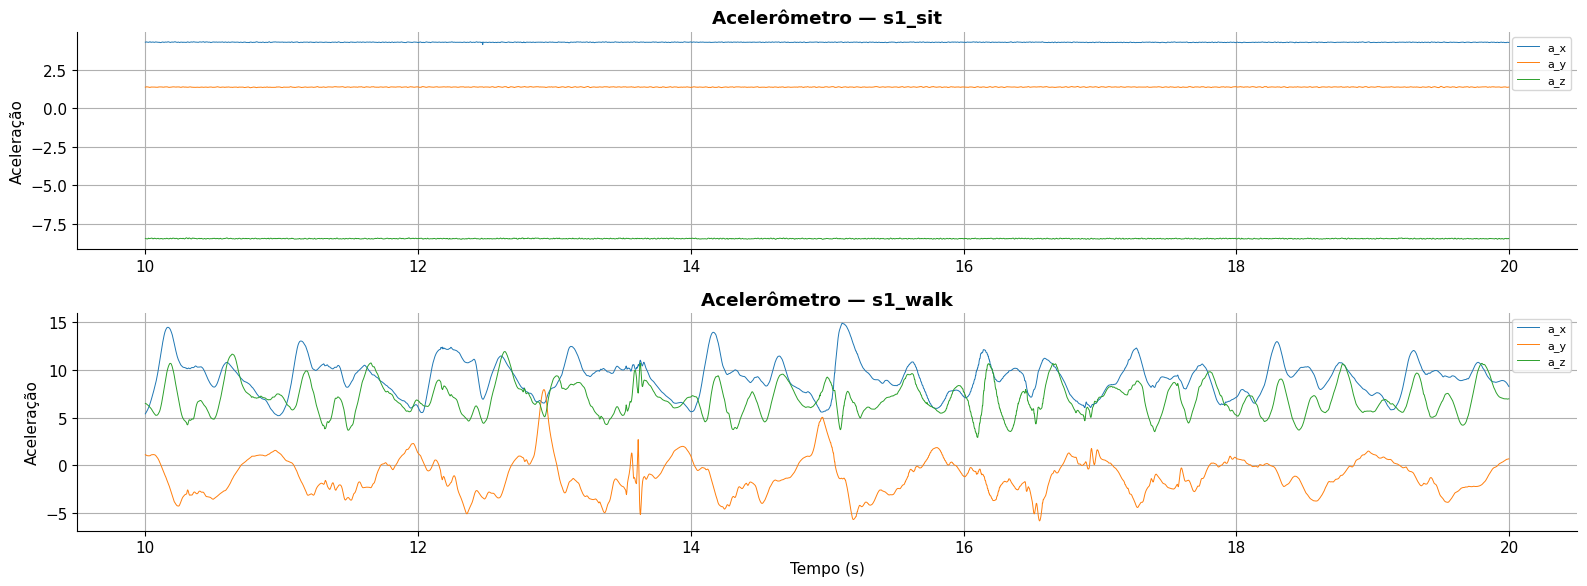

Nota: O acelerômetro pode ser usado para filtrar artefatos de movimento (D3.2)


In [13]:
# Comparar acelerômetro sit vs walk
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=False)

for ax, cond in zip(axes, ['s1_sit', 's1_walk']):
    rec = wfdb.rdrecord(os.path.join(BASE_PATH, cond))
    fs = rec.fs
    start, end = int(10*fs), int(20*fs)
    
    for ch_name in ['a_x', 'a_y', 'a_z']:
        if ch_name in rec.sig_name:
            idx = rec.sig_name.index(ch_name)
            time = np.arange(start, end) / fs
            ax.plot(time, rec.p_signal[start:end, idx], linewidth=0.7, label=ch_name)
    
    ax.set_ylabel('Aceleração')
    ax.set_title(f'Acelerômetro — {cond}', fontweight='bold')
    ax.legend(fontsize=8)

axes[-1].set_xlabel('Tempo (s)')
plt.tight_layout()
plt.show()
print("Nota: O acelerômetro pode ser usado para filtrar artefatos de movimento (D3.2)")

## 6. Avaliação de Qualidade do Sinal PPG — VERSÃO CORRIGIDA
Avaliar cada registro para: saturação (clipping), flat-line, SNR e FC plausível.

### ⚠️ Correções aplicadas (v2):
1. **Flat-line**: threshold anterior (`std × 0.001`) era agressivo demais para sinais 
   com valores brutos na casa de 60.000+. Novo threshold usa percentil da derivada.
2. **SNR**: Calculado sobre sinal **filtrado** (não bruto), pois o bruto tem componente 
   DC enorme que distorce o cálculo.
3. **Melhor canal PPG**: Testa `pleth_1` a `pleth_6` e escolhe o de maior SNR.
4. Classificação mais permissiva: LOW_SNR sozinho não descarta (apenas marca).

In [14]:
# Imports necessários para avaliação de qualidade
from scipy.signal import butter, filtfilt, find_peaks, welch


def find_best_pleth_channel(record_name):
    """
    Testa pleth_1 a pleth_6 e retorna o canal com maior SNR cardíaco.
    Calcula SNR sobre o sinal FILTRADO para evitar distorção pelo DC offset.
    """
    rec = wfdb.rdrecord(os.path.join(BASE_PATH, record_name))
    fs = rec.fs
    
    nyq = fs / 2
    b, a = butter(3, [0.5/nyq, 8.0/nyq], btype='bandpass')
    
    best_ch = None
    best_snr = -999
    results = []
    
    for ch_name in rec.sig_name:
        if not ch_name.startswith('pleth'):
            continue
        
        ch_idx = rec.sig_name.index(ch_name)
        ppg_raw = rec.p_signal[:, ch_idx]
        
        try:
            ppg_filt = filtfilt(b, a, ppg_raw)
        except:
            continue
        
        freqs_psd, psd = welch(ppg_filt, fs=fs, nperseg=min(len(ppg_filt), int(8*fs)))
        cardiac = (freqs_psd >= 0.5) & (freqs_psd <= 4.0)
        noise = (freqs_psd > 4.0) & (freqs_psd <= 20.0)
        
        p_cardiac = np.trapz(psd[cardiac], freqs_psd[cardiac]) if cardiac.sum() > 0 else 0
        p_noise = np.trapz(psd[noise], freqs_psd[noise]) if noise.sum() > 0 else 1e-15
        snr = 10 * np.log10(p_cardiac / p_noise) if p_noise > 0 else -99
        
        results.append({'channel': ch_name, 'snr_db': round(snr, 1)})
        
        if snr > best_snr:
            best_snr = snr
            best_ch = ch_name
    
    return best_ch, best_snr, results


def assess_ppg_quality_v2(record_name, pleth_channel=None):
    """
    Avalia qualidade do PPG — versão corrigida com thresholds calibrados.
    Se pleth_channel=None, automaticamente seleciona o melhor canal.
    """
    rec = wfdb.rdrecord(os.path.join(BASE_PATH, record_name))
    fs = rec.fs
    
    if pleth_channel is None:
        pleth_channel, auto_snr, _ = find_best_pleth_channel(record_name)
        if pleth_channel is None:
            return {'record': record_name, 'quality': 'NO_PLETH'}
    
    ch_idx = rec.sig_name.index(pleth_channel)
    ppg_raw = rec.p_signal[:, ch_idx]
    
    nyq = fs / 2
    b, a = butter(3, [0.5/nyq, 8.0/nyq], btype='bandpass')
    try:
        ppg_filt = filtfilt(b, a, ppg_raw)
    except:
        return {'record': record_name, 'pleth_channel': pleth_channel, 'quality': 'FILTER_ERROR'}
    
    # 1. Clipping (sobre sinal bruto)
    sig_range = ppg_raw.max() - ppg_raw.min()
    if sig_range == 0:
        return {'record': record_name, 'pleth_channel': pleth_channel, 'quality': 'FLATLINE_TOTAL'}
    upper = np.abs(ppg_raw - ppg_raw.max()) < (sig_range * 0.002)
    lower = np.abs(ppg_raw - ppg_raw.min()) < (sig_range * 0.002)
    clip_frac = (upper.sum() + lower.sum()) / len(ppg_raw)
    
    # 2. Flat-line CORRIGIDO
    diff_filt = np.abs(np.diff(ppg_filt))
    p1_diff = np.percentile(diff_filt, 1)
    threshold_flat = max(p1_diff * 2, 1e-8)
    is_flat = diff_filt < threshold_flat
    min_flat_samples = int(0.5 * fs)
    flat_segments = 0
    count = 0
    for val in is_flat:
        if val:
            count += 1
        else:
            if count >= min_flat_samples:
                flat_segments += count
            count = 0
    if count >= min_flat_samples:
        flat_segments += count
    flat_frac = flat_segments / len(ppg_filt)
    
    # 3. FC via picos
    peaks, _ = find_peaks(ppg_filt, distance=int(0.4 * fs),
                          height=np.percentile(ppg_filt, 50))
    hr_mean, hr_std = None, None
    if len(peaks) > 2:
        intervals = np.diff(peaks) / fs
        valid = (intervals > 0.3) & (intervals < 2.0)
        if valid.sum() > 1:
            hr = 60.0 / intervals[valid]
            hr_mean = hr.mean()
            hr_std = hr.std()
    
    # 4. SNR
    freqs_psd, psd = welch(ppg_filt, fs=fs, nperseg=min(len(ppg_filt), int(8*fs)))
    cardiac = (freqs_psd >= 0.5) & (freqs_psd <= 4.0)
    noise = (freqs_psd > 4.0) & (freqs_psd <= 20.0)
    p_cardiac = np.trapz(psd[cardiac], freqs_psd[cardiac]) if cardiac.sum() > 0 else 0
    p_noise = np.trapz(psd[noise], freqs_psd[noise]) if noise.sum() > 0 else 1e-15
    snr_db = 10 * np.log10(p_cardiac / p_noise) if p_noise > 0 else 0
    
    # 5. Classificar
    issues = []
    if clip_frac > 0.05:
        issues.append('CLIPPING')
    if flat_frac > 0.05:
        issues.append('FLATLINE')
    if hr_mean is not None and (hr_mean < 35 or hr_mean > 200):
        issues.append('HR_ABNORMAL')
    if hr_std is not None and hr_std > 40:
        issues.append('HR_IRREGULAR')
    if snr_db < -5:
        issues.append('VERY_LOW_SNR')
    
    structural_issues = [i for i in issues if i != 'VERY_LOW_SNR']
    if len(structural_issues) == 0 and snr_db >= 0:
        quality = 'GOOD'
    elif len(structural_issues) == 0:
        quality = 'ACCEPTABLE'
    elif len(structural_issues) <= 1:
        quality = 'ACCEPTABLE'
    else:
        quality = 'POOR'
    
    return {
        'record': record_name,
        'pleth_channel': pleth_channel,
        'clip_frac': round(clip_frac, 4),
        'flat_frac': round(flat_frac, 4),
        'hr_mean': round(hr_mean, 1) if hr_mean else None,
        'hr_std': round(hr_std, 1) if hr_std else None,
        'n_peaks': len(peaks),
        'snr_db': round(snr_db, 1),
        'issues': ', '.join(issues) if issues else 'none',
        'quality': quality
    }

print("✅ Funções de qualidade definidas (find_best_pleth_channel + assess_ppg_quality_v2)")


✅ Funções de qualidade definidas (find_best_pleth_channel + assess_ppg_quality_v2)


In [15]:
# Avaliar TODOS os 66 registros com detector corrigido
print("Avaliando qualidade (v2 — thresholds corrigidos)...")
print("=" * 60)

quality_results = []
for i, rec_name in enumerate(sorted(all_hea)):
    result = assess_ppg_quality_v2(rec_name)
    quality_results.append(result)
    if (i+1) % 22 == 0:
        print(f"  Progresso: {i+1}/{len(all_hea)}")

df_quality = pd.DataFrame(quality_results)

# Calcular totais
total = len(df_quality)
good = (df_quality['quality'] == 'GOOD').sum()
acceptable = (df_quality['quality'] == 'ACCEPTABLE').sum()
poor = total - good - acceptable

print(f"\n{'='*60}")
print("AVALIAÇÃO DE QUALIDADE — v2 CORRIGIDA")
print(f"{'='*60}")
print(f"\n📊 Classificação:")
print(df_quality['quality'].value_counts().to_string())
print(f"\nAprovados (GOOD + ACCEPTABLE): {good + acceptable}/{total} ({(good+acceptable)/total*100:.0f}%)")

# Canais selecionados
if 'pleth_channel' in df_quality.columns:
    print(f"\n📊 Canais PPG selecionados automaticamente:")
    print(df_quality['pleth_channel'].value_counts().to_string())

# Problemas
all_issues = df_quality['issues'].str.split(', ').explode()
all_issues = all_issues[all_issues != 'none']
if len(all_issues) > 0:
    print(f"\n📊 Problemas detectados:")
    print(all_issues.value_counts().to_string())

# Sanity-check FC
valid_hr = df_quality[df_quality['hr_mean'].notna()]
if len(valid_hr) > 0:
    print(f"\n📊 Sanity-check FC (D7.4):")
    print(f"   FC média: {valid_hr['hr_mean'].mean():.1f} ± {valid_hr['hr_mean'].std():.1f} bpm")
    print(f"   Range: {valid_hr['hr_mean'].min():.0f} — {valid_hr['hr_mean'].max():.0f} bpm")


Avaliando qualidade (v2 — thresholds corrigidos)...
  Progresso: 22/66
  Progresso: 44/66
  Progresso: 66/66

AVALIAÇÃO DE QUALIDADE — v2 CORRIGIDA

📊 Classificação:
quality
GOOD    66

Aprovados (GOOD + ACCEPTABLE): 66/66 (100%)

📊 Canais PPG selecionados automaticamente:
pleth_channel
pleth_6    33
pleth_3    13
pleth_4    10
pleth_5     8
pleth_2     1
pleth_1     1

📊 Sanity-check FC (D7.4):
   FC média: 85.0 ± 11.6 bpm
   Range: 55 — 121 bpm


In [16]:
# Fluxograma de atrito (D3.6) — v2
total = len(df_quality)
good = (df_quality['quality'] == 'GOOD').sum()
acceptable = (df_quality['quality'] == 'ACCEPTABLE').sum()
poor = total - good - acceptable
n_subj_approved = df_quality[df_quality['quality'].isin(['GOOD','ACCEPTABLE'])]['record'].apply(lambda x: x.split('_')[0]).nunique()

print("=" * 60)
print("FLUXOGRAMA DE ATRITO (D3.6) — v2")
print("=" * 60)
print(f"""
Dataset total:                        {total} registros ({df_inv['subject'].nunique()} sujeitos × {df_inv['condition'].nunique()} condições)
  ├── Qualidade GOOD:                 {good}
  ├── Qualidade ACCEPTABLE:           {acceptable}
  └── Qualidade POOR:                 {poor}

Registros aprovados para análise:     {good + acceptable}
Sujeitos com ≥1 registro aprovado:    {n_subj_approved}
Taxa de aprovação:                     {(good+acceptable)/total*100:.1f}%
""")

# Detalhes dos POOR
poor_recs = df_quality[df_quality['quality'] == 'POOR']
if len(poor_recs) > 0:
    print(f"Registros descartados ({len(poor_recs)}):")
    print(poor_recs[['record', 'pleth_channel', 'issues', 'snr_db', 'hr_mean']].to_string(index=False))
else:
    print("✅ Nenhum registro descartado!")


FLUXOGRAMA DE ATRITO (D3.6) — v2

Dataset total:                        66 registros (22 sujeitos × 3 condições)
  ├── Qualidade GOOD:                 66
  ├── Qualidade ACCEPTABLE:           0
  └── Qualidade POOR:                 0

Registros aprovados para análise:     66
Sujeitos com ≥1 registro aprovado:    22
Taxa de aprovação:                     100.0%

✅ Nenhum registro descartado!


## 7. Documentação de Limitações para o Relatório Final

### ⚠️ Limitação 1: Ausência de ABP contínuo
O dataset contém PA apenas como medida pontual (início e final da gravação). 
Isso limita a abordagem a **predição de PA estática** a partir de features do PPG.

**✅ Mitigação**: O header contém `bp_sys_start`, `bp_sys_end`, `bp_dia_start`, `bp_dia_end`.
Isso permite usar tanto PA pré quanto pós gravação, e analisar **variação de PA com atividade**.

### ⚠️ Limitação 2: Amostra jovem e predominantemente masculina
- Mediana de idade: 25 anos
- 68% masculino (15M/7F)
- Apenas 2 sujeitos com PAS ≥ 140 mmHg

### ⚠️ Limitação 3: Sem informação de etnia

### ✅ Oportunidade: PTT (Pulse Transit Time)
O dataset tem ECG + PPG simultâneos → possível calcular PTT, que tem correlação
forte com PA (Islam et al. 2022, Art. 8: PPG+ECG supera PPG isolado).

## 8. Salvar Dados do NB01 para Pré-processamento

In [17]:
# Salvar inventário
df_inv.to_csv(os.path.join(BASE_PATH, '_inventory.csv'), index=False)
df_demo.to_csv(os.path.join(BASE_PATH, '_demographics.csv'), index=False)
df_quality.to_csv(os.path.join(BASE_PATH, '_quality_v2.csv'), index=False)

# Lista de registros aprovados (com melhor canal)
approved = df_quality[df_quality['quality'].isin(['GOOD', 'ACCEPTABLE'])].copy()
approved[['record', 'pleth_channel']].to_csv(
    os.path.join(BASE_PATH, '_approved_records.csv'), index=False)

n_subj = approved['record'].apply(lambda x: x.split('_')[0]).nunique()
print(f"✅ Arquivos salvos em {BASE_PATH}:")
print(f"   _inventory.csv ({len(df_inv)} registros)")
print(f"   _demographics.csv ({len(df_demo)} sujeitos)")
print(f"   _quality_v2.csv ({len(df_quality)} avaliações)")
print(f"   _approved_records.csv ({len(approved)} aprovados, {n_subj} sujeitos)")


✅ Arquivos salvos em C:\Users\USER B. Godoi\.openclaw\workspace\datasets\PTT_PPG:
   _inventory.csv (66 registros)
   _demographics.csv (22 sujeitos)
   _quality_v2.csv (66 avaliações)
   _approved_records.csv (66 aprovados, 22 sujeitos)


# Notebook 02 — Pré-processamento, Features e PTT
**Objetivo**: Pipeline completo — filtragem, detecção de picos, extração de features 
morfológicas, cálculo de PTT (ECG→PPG), e vinculação com PA de referência.

### Correções aplicadas (v2):
1. Usar canal PPG selecionado automaticamente (melhor SNR)
2. Detecção de picos com validação de intervalo fisiológico
3. Features com proteção contra divisão por zero
4. **PTT (Pulse Transit Time)** como feature adicional — ECG R-peak → PPG peak
5. PA de referência inclui `_start` E `_end` + metadados de condição

## 9. Imports e Carregamento dos Aprovados

In [19]:
# Imports para pré-processamento
from scipy.signal import butter, filtfilt, savgol_filter, find_peaks
from scipy.stats import skew, kurtosis
from scipy.integrate import simpson
import warnings
warnings.filterwarnings('ignore')

# Carregar registros aprovados (com melhor canal PPG)
approved_path = os.path.join(BASE_PATH, '_approved_records.csv')
if os.path.exists(approved_path):
    df_approved = pd.read_csv(approved_path)
    approved_records = df_approved['record'].tolist()
    if 'pleth_channel' in df_approved.columns:
        channel_map = dict(zip(df_approved['record'], df_approved['pleth_channel']))
    else:
        channel_map = {r: 'pleth_1' for r in approved_records}
    print(f"✅ Registros aprovados: {len(approved_records)}")
    print(f"   Sujeitos: {len(set(r.split('_')[0] for r in approved_records))}")
else:
    # Fallback: usar todos os registros com pleth_1
    approved_records = sorted([f.replace('.hea','') for f in os.listdir(BASE_PATH) if f.endswith('.hea')])
    channel_map = {r: 'pleth_1' for r in approved_records}
    print(f"⚠️ Arquivo de aprovados não encontrado. Usando todos: {len(approved_records)}")

print(f"\nPrimeiros registros: {approved_records[:5]}")


✅ Registros aprovados: 66
   Sujeitos: 22

Primeiros registros: ['s10_run', 's10_sit', 's10_walk', 's11_run', 's11_sit']


## 10. Pipeline de Filtragem
Savitzky-Golay → Butterworth (0.5–8 Hz) → Normalização z-score robusta.

In [20]:
def preprocess_ppg(ppg_raw, fs, 
                   savgol_window=19, savgol_order=4,
                   butter_order=3, freq_low=0.5, freq_high=8.0):
    """Pipeline de pré-processamento do PPG (D10.1, D1.1, D6.1, D7.3)."""
    # 1. Savitzky-Golay
    win = min(savgol_window, len(ppg_raw) - 1)
    if win % 2 == 0:
        win -= 1
    ppg_smooth = savgol_filter(ppg_raw, window_length=win, polyorder=savgol_order)
    
    # 2. Butterworth passa-banda + filtfilt
    nyq = fs / 2
    if freq_high >= nyq:
        freq_high = nyq - 1
    b, a = butter(butter_order, [freq_low / nyq, freq_high / nyq], btype='bandpass')
    ppg_filt = filtfilt(b, a, ppg_smooth)
    
    # 3. Normalização z-score robusta (mediana / MAD)
    median = np.median(ppg_filt)
    mad = np.median(np.abs(ppg_filt - median))
    if mad > 0:
        ppg_norm = (ppg_filt - median) / (1.4826 * mad)
    else:
        ppg_norm = ppg_filt - median
    
    return {
        'raw': ppg_raw, 'smoothed': ppg_smooth,
        'filtered': ppg_filt, 'normalized': ppg_norm, 'fs': fs
    }


def preprocess_ecg(ecg_raw, fs, butter_order=3, freq_low=0.5, freq_high=40.0):
    """Pipeline de pré-processamento do ECG para detecção de R-peaks."""
    nyq = fs / 2
    b, a = butter(butter_order, [freq_low/nyq, min(freq_high/nyq, 0.99)], btype='bandpass')
    ecg_filt = filtfilt(b, a, ecg_raw)
    return ecg_filt

print("✅ Funções de pré-processamento definidas (preprocess_ppg + preprocess_ecg)")


✅ Funções de pré-processamento definidas (preprocess_ppg + preprocess_ecg)


### 10a. Visualizar filtragem

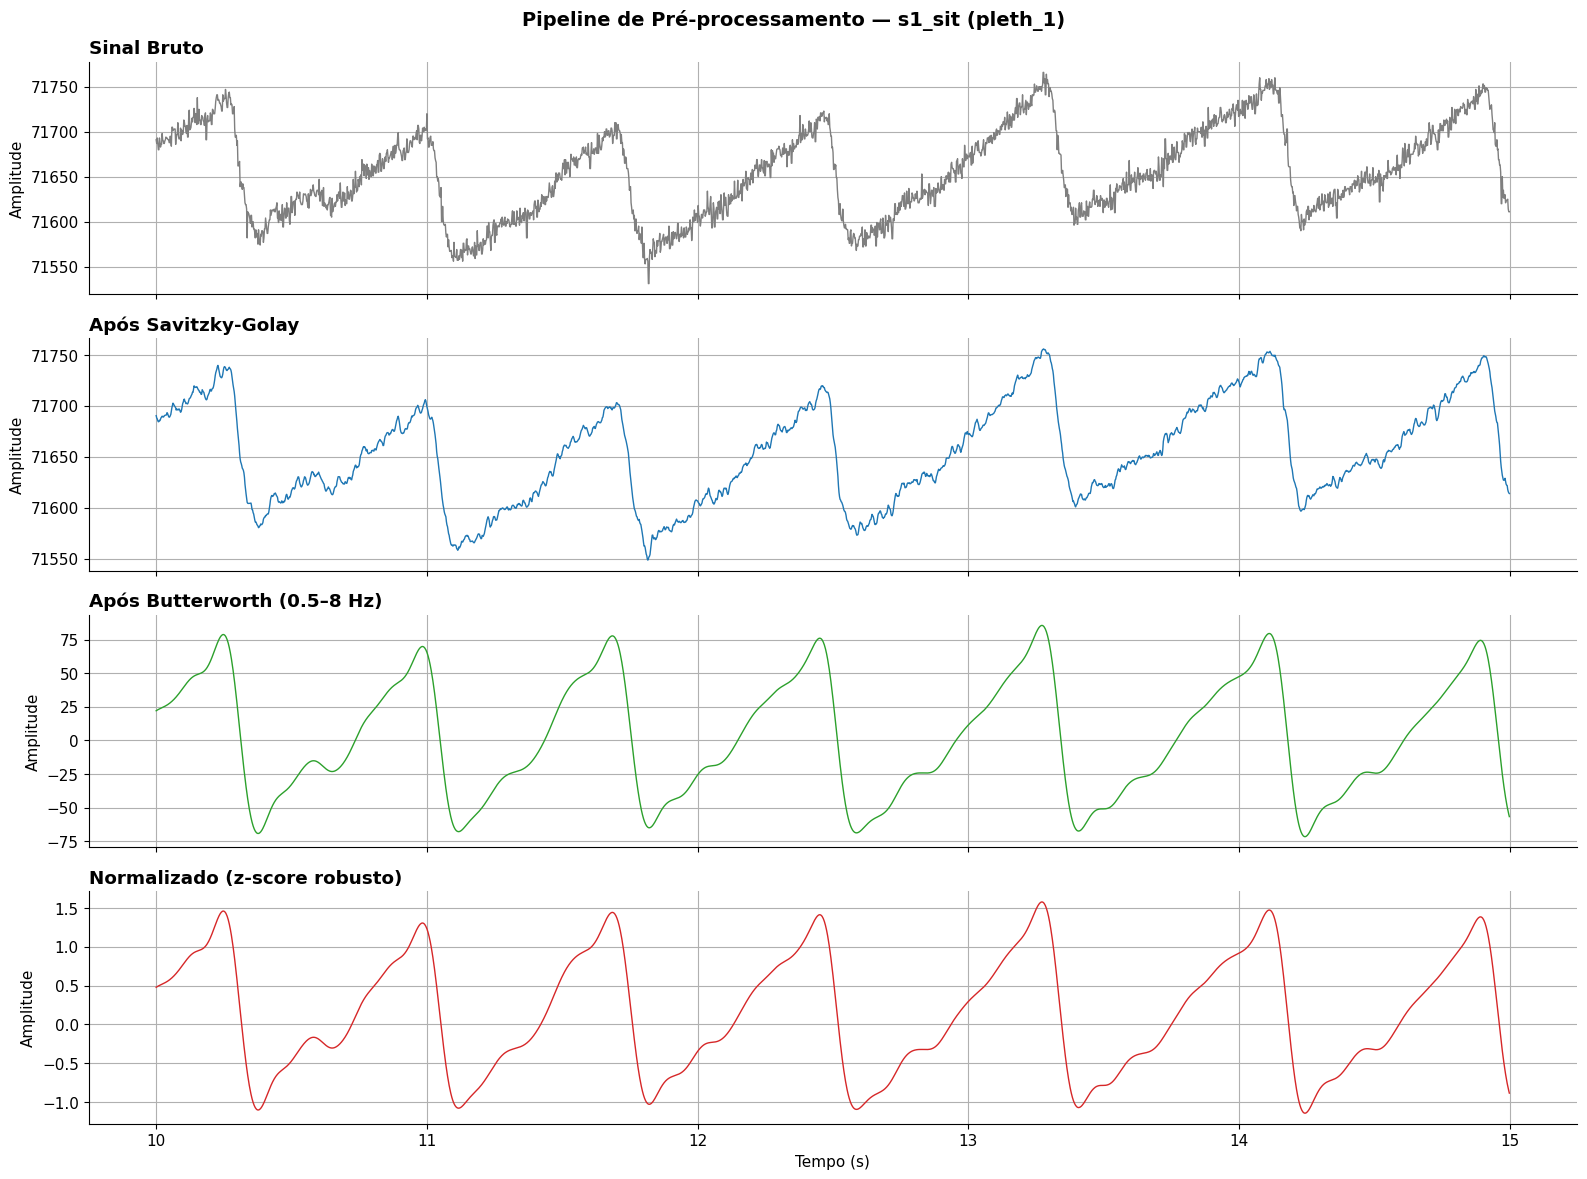

In [21]:
# Demonstração com s1_sit
demo_rec = wfdb.rdrecord(os.path.join(BASE_PATH, 's1_sit'))
fs = demo_rec.fs

# Usar melhor canal PPG
best_ch = 'pleth_1'
ppg_idx = demo_rec.sig_name.index(best_ch)
ppg_raw = demo_rec.p_signal[:, ppg_idx]

result = preprocess_ppg(ppg_raw, fs)

# Plotar 5s
s, e = int(10*fs), int(15*fs)
time = np.arange(s, e) / fs

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
stages = [
    ('raw', 'Sinal Bruto', 'tab:gray'),
    ('smoothed', 'Após Savitzky-Golay', 'tab:blue'),
    ('filtered', 'Após Butterworth (0.5–8 Hz)', 'tab:green'),
    ('normalized', 'Normalizado (z-score robusto)', 'tab:red')
]
for ax, (key, title, color) in zip(axes, stages):
    ax.plot(time, result[key][s:e], color=color, linewidth=1)
    ax.set_ylabel('Amplitude')
    ax.set_title(title, loc='left', fontweight='bold')
axes[-1].set_xlabel('Tempo (s)')
fig.suptitle(f'Pipeline de Pré-processamento — s1_sit ({best_ch})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 11. Detecção de Picos — Versão Corrigida
Correções:
1. Validar intervalos entre picos ANTES de retornar
2. Remover picos duplicados após refinamento
3. Filtrar ciclos com duração fora de 0.33–2.0s (30–180 bpm)

In [22]:
def detect_systolic_peaks_v2(ppg_filtered, fs,
                           integration_window_ms=250,
                           refractory_ms=400,
                           height_percentile=30):
    """
    Detecta picos sistólicos — v2 com validação de intervalos.
    Retorna apenas picos que formam ciclos fisiologicamente válidos.
    """
    # 1. Derivada de 5 pontos
    h_d = np.array([-1, -2, 0, 2, 1]) / 8.0
    ppg_deriv = np.convolve(ppg_filtered, h_d, mode='same')
    
    # 2. Quadrado
    ppg_sq = ppg_deriv ** 2
    
    # 3. Média móvel
    win = int(round(integration_window_ms / 1000 * fs))
    kernel = np.ones(max(win,1)) / max(win,1)
    ppg_int = np.convolve(ppg_sq, kernel, mode='same')
    
    # 4. Detectar picos na curva integrada
    min_distance = int(refractory_ms / 1000 * fs)
    height_thresh = np.percentile(ppg_int, height_percentile)
    peaks_raw, _ = find_peaks(ppg_int, distance=min_distance, height=height_thresh)
    
    # 5. Refinar: mapear para máximo local no sinal original
    search_win = int(0.15 * fs)
    refined = []
    for p in peaks_raw:
        left = max(0, p - search_win)
        right = min(len(ppg_filtered), p + search_win)
        local_max = left + np.argmax(ppg_filtered[left:right])
        refined.append(local_max)
    
    refined = np.array(sorted(set(refined)))
    
    if len(refined) < 3:
        return refined, {'hr_mean': None, 'hr_std': None, 'n_peaks': len(refined),
                         'deriv': ppg_deriv, 'squared': ppg_sq, 'integrated': ppg_int}
    
    # 6. Filtrar por intervalo fisiológico (0.33–2.0s = 30–180 bpm)
    valid_peaks = [refined[0]]
    for i in range(1, len(refined)):
        interval = (refined[i] - valid_peaks[-1]) / fs
        if 0.33 <= interval <= 2.0:
            valid_peaks.append(refined[i])
        elif interval > 2.0:
            valid_peaks.append(refined[i])
    
    valid_peaks = np.array(valid_peaks)
    
    # FC
    hr_mean, hr_std = None, None
    if len(valid_peaks) > 2:
        intervals = np.diff(valid_peaks) / fs
        physio = (intervals >= 0.33) & (intervals <= 2.0)
        if physio.sum() > 1:
            hr = 60.0 / intervals[physio]
            hr_mean = hr.mean()
            hr_std = hr.std()
    
    return valid_peaks, {
        'hr_mean': hr_mean, 'hr_std': hr_std, 'n_peaks': len(valid_peaks),
        'deriv': ppg_deriv, 'squared': ppg_sq, 'integrated': ppg_int
    }


def detect_ecg_r_peaks(ecg_filtered, fs):
    """Detecta R-peaks do ECG para cálculo de PTT."""
    h_d = np.array([-1, -2, 0, 2, 1]) / 8.0
    ecg_d = np.convolve(ecg_filtered, h_d, mode='same')
    ecg_sq = ecg_d ** 2
    
    win = int(0.15 * fs)
    kernel = np.ones(max(win,1)) / max(win,1)
    ecg_int = np.convolve(ecg_sq, kernel, mode='same')
    
    min_dist = int(0.3 * fs)
    height_thresh = np.percentile(ecg_int, 40)
    peaks, _ = find_peaks(ecg_int, distance=min_dist, height=height_thresh)
    
    # Refinar para máximo no sinal original
    search_win = int(0.05 * fs)
    refined = []
    for p in peaks:
        left = max(0, p - search_win)
        right = min(len(ecg_filtered), p + search_win)
        local_max = left + np.argmax(ecg_filtered[left:right])
        refined.append(local_max)
    
    return np.array(sorted(set(refined)))

print("✅ Funções de detecção de picos definidas (detect_systolic_peaks_v2 + detect_ecg_r_peaks)")


✅ Funções de detecção de picos definidas (detect_systolic_peaks_v2 + detect_ecg_r_peaks)


### 11a. Visualizar detecção de picos (PPG + ECG)

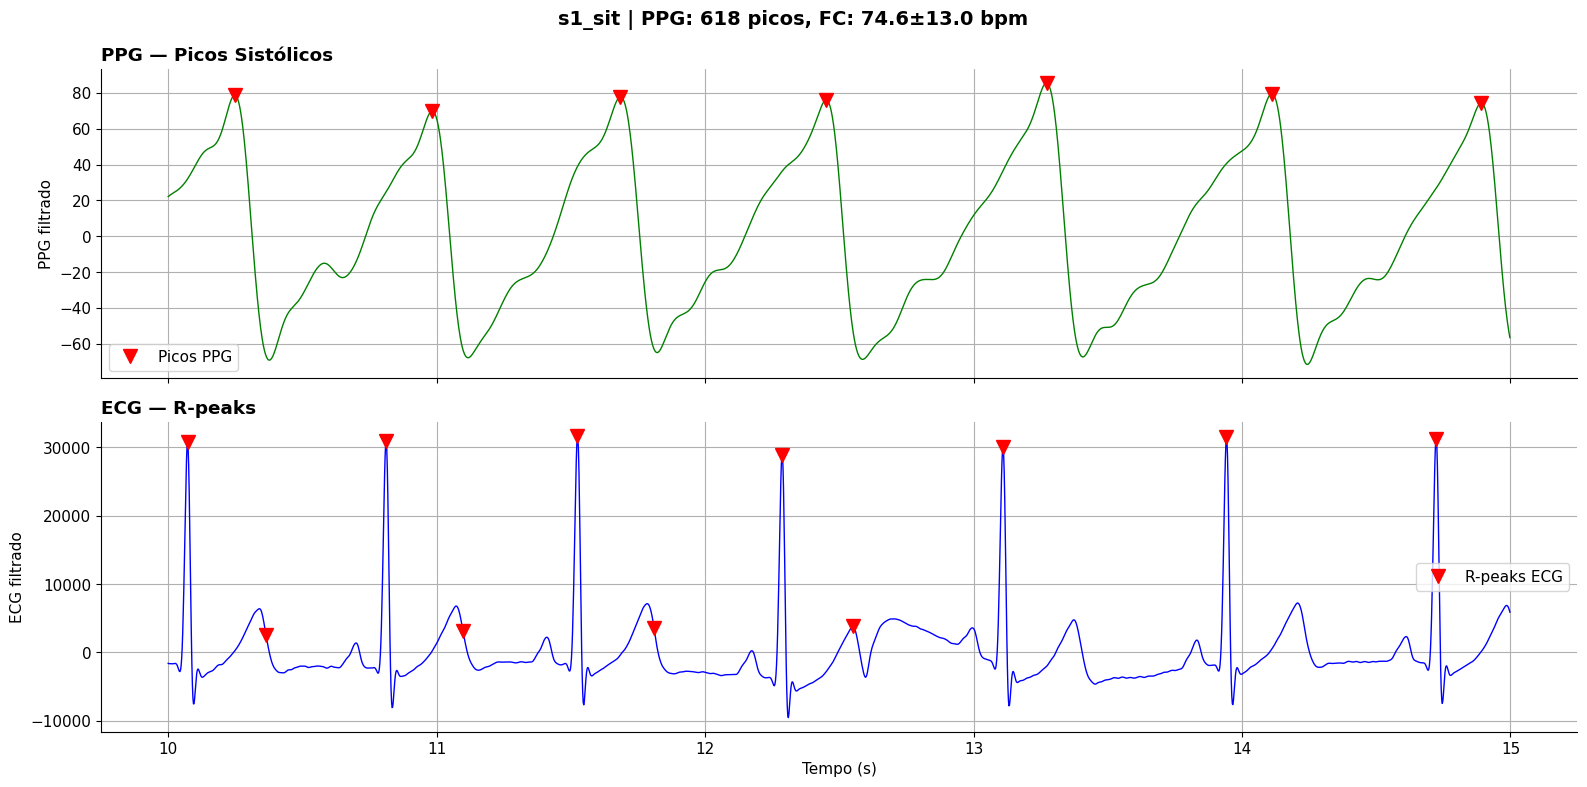

In [23]:
# Demonstrar detecção de picos PPG e ECG
ppg_filt = result['filtered']
peaks_ppg, peak_info = detect_systolic_peaks_v2(ppg_filt, fs)

# ECG
ecg_idx = demo_rec.sig_name.index('ecg')
ecg_raw = demo_rec.p_signal[:, ecg_idx]
ecg_filt = preprocess_ecg(ecg_raw, fs)
peaks_ecg = detect_ecg_r_peaks(ecg_filt, fs)

# Plotar 5s
s, e = int(10*fs), int(15*fs)
time = np.arange(s, e) / fs

fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# PPG + picos
ppg_peaks_in = peaks_ppg[(peaks_ppg >= s) & (peaks_ppg < e)]
axes[0].plot(time, ppg_filt[s:e], 'g-', linewidth=1)
axes[0].plot(ppg_peaks_in/fs, ppg_filt[ppg_peaks_in], 'rv', markersize=10, label='Picos PPG')
axes[0].set_ylabel('PPG filtrado')
axes[0].set_title('PPG — Picos Sistólicos', loc='left', fontweight='bold')
axes[0].legend()

# ECG + R-peaks
ecg_peaks_in = peaks_ecg[(peaks_ecg >= s) & (peaks_ecg < e)]
axes[1].plot(time, ecg_filt[s:e], 'b-', linewidth=1)
axes[1].plot(ecg_peaks_in/fs, ecg_filt[ecg_peaks_in], 'rv', markersize=10, label='R-peaks ECG')
axes[1].set_ylabel('ECG filtrado')
axes[1].set_xlabel('Tempo (s)')
axes[1].set_title('ECG — R-peaks', loc='left', fontweight='bold')
axes[1].legend()

hr_str = f"{peak_info['hr_mean']:.1f}±{peak_info['hr_std']:.1f}" if peak_info['hr_mean'] else "N/A"
fig.suptitle(f's1_sit | PPG: {peak_info["n_peaks"]} picos, FC: {hr_str} bpm', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 12. Cálculo do PTT (Pulse Transit Time)
PTT = tempo entre R-peak do ECG e pico sistólico do PPG no mesmo batimento.
Correlação com PA demonstrada no Art. 8: PPG+ECG supera PPG isolado (D1.3, D8.3).

In [24]:
def compute_ptt(ecg_r_peaks, ppg_sys_peaks, fs, max_delay_s=0.5):
    """
    Calcula PTT para cada batimento.
    PTT = tempo do R-peak ECG ao próximo pico sistólico PPG.
    """
    ptt_values = []
    ppg_used = []
    ecg_used = []
    
    for r_peak in ecg_r_peaks:
        candidates = ppg_sys_peaks[ppg_sys_peaks > r_peak]
        if len(candidates) == 0:
            continue
        
        next_ppg = candidates[0]
        delay = (next_ppg - r_peak) / fs
        
        if 0.05 <= delay <= max_delay_s:
            ptt_values.append(delay)
            ecg_used.append(r_peak)
            ppg_used.append(next_ppg)
    
    return np.array(ptt_values), np.array(ecg_used), np.array(ppg_used)

print("✅ Função compute_ptt definida")


✅ Função compute_ptt definida


📊 PTT — s1_sit:
   Batimentos com PTT válido: 587
   PTT médio: 177.5 ± 42.1 ms
   Range: 156.0 — 478.0 ms


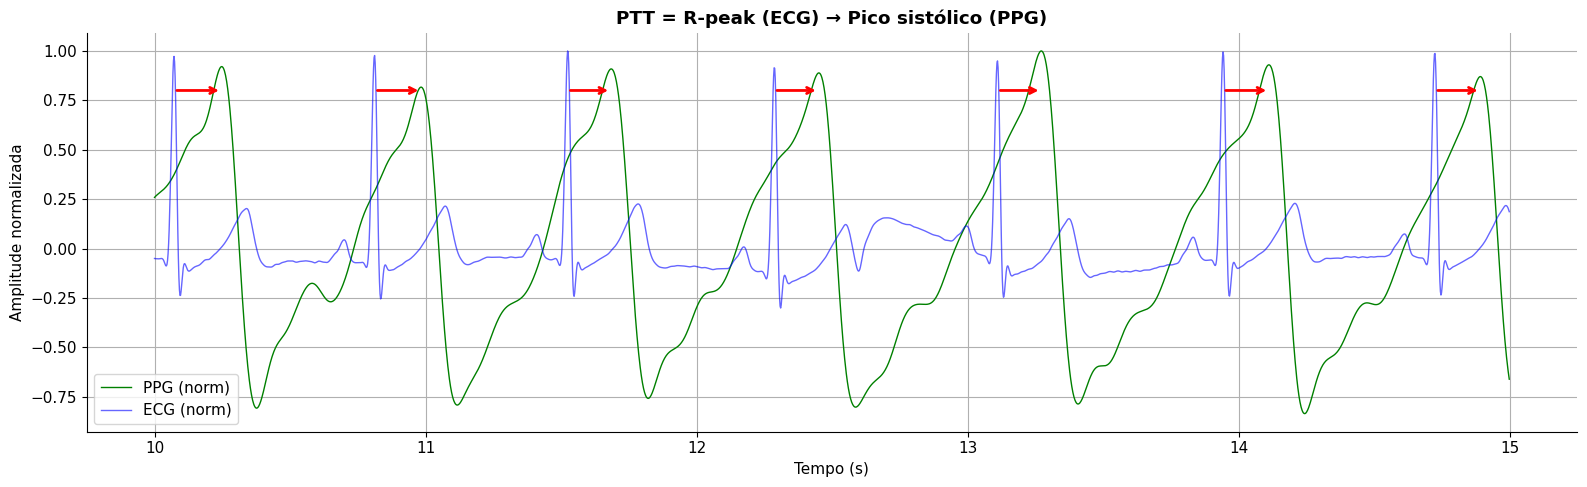

In [25]:
# Demonstrar PTT para s1_sit
ptt_vals, ecg_used, ppg_used = compute_ptt(peaks_ecg, peaks_ppg, fs)

print(f"📊 PTT — s1_sit:")
print(f"   Batimentos com PTT válido: {len(ptt_vals)}")
if len(ptt_vals) > 0:
    print(f"   PTT médio: {ptt_vals.mean()*1000:.1f} ± {ptt_vals.std()*1000:.1f} ms")
    print(f"   Range: {ptt_vals.min()*1000:.1f} — {ptt_vals.max()*1000:.1f} ms")

# Visualizar PTT em 5s
fig, ax = plt.subplots(figsize=(16, 5))
s, e = int(10*fs), int(15*fs)
time = np.arange(s, e) / fs

ax.plot(time, ppg_filt[s:e] / np.max(np.abs(ppg_filt[s:e])), 'g-', linewidth=1, label='PPG (norm)')
ax.plot(time, ecg_filt[s:e] / np.max(np.abs(ecg_filt[s:e])), 'b-', linewidth=1, alpha=0.6, label='ECG (norm)')

# Mostrar PTT como setas
for r, p in zip(ecg_used, ppg_used):
    if s <= r < e and s <= p < e:
        ax.annotate('', xy=(p/fs, 0.8), xytext=(r/fs, 0.8),
                    arrowprops=dict(arrowstyle='->', color='red', lw=2))

ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Amplitude normalizada')
ax.set_title('PTT = R-peak (ECG) → Pico sistólico (PPG)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## 13. Extração de Features — Versão Corrigida
Correções:
1. Proteção contra divisão por zero em todas as razões
2. Filtro de duração do ciclo (descarta < 0.33s ou > 2.0s)
3. PTT como feature adicional

In [26]:
def extract_pulse_features_v2(ppg_segment, fs):
    """Extrai features morfológicas — v2 com proteção contra divisão por zero."""
    n = len(ppg_segment)
    duration_s = n / fs
    
    if n < int(0.33 * fs) or duration_s > 2.0:
        return None
    
    seg_min = ppg_segment.min()
    seg_max = ppg_segment.max()
    seg_range = seg_max - seg_min
    
    if seg_range < 1e-10:
        return None
    
    features = {}
    seg_norm = (ppg_segment - seg_min) / seg_range
    
    # TEMPORAIS
    features['cardiac_period_s'] = duration_s
    features['heart_rate_bpm'] = 60.0 / duration_s
    
    peak_idx = np.argmax(seg_norm)
    sut = peak_idx / fs
    dt = (n - peak_idx) / fs
    features['systolic_upstroke_time_s'] = sut
    features['diastolic_time_s'] = dt
    features['sut_dt_ratio'] = sut / dt if dt > 0.02 else np.nan
    
    # Larguras
    for pct in [10, 25, 33, 50, 66, 75]:
        threshold = pct / 100.0
        above = seg_norm >= threshold
        
        if above.sum() > 0:
            indices = np.where(above)[0]
            total_w = (indices[-1] - indices[0]) / fs
            
            sys_idx = indices[indices <= peak_idx]
            dia_idx = indices[indices > peak_idx]
            
            sw = (sys_idx[-1] - sys_idx[0]) / fs if len(sys_idx) > 1 else 0
            dw = (dia_idx[-1] - dia_idx[0]) / fs if len(dia_idx) > 1 else 0
            
            features[f'w{pct}_total'] = total_w
            features[f'w{pct}_sys'] = sw
            features[f'w{pct}_dia'] = dw
            features[f'w{pct}_ratio'] = dw / sw if sw > 0.005 else np.nan
        else:
            features[f'w{pct}_total'] = 0
            features[f'w{pct}_sys'] = 0
            features[f'w{pct}_dia'] = 0
            features[f'w{pct}_ratio'] = np.nan
    
    # AMPLITUDE
    features['amplitude'] = seg_range
    features['peak_value'] = seg_max
    features['valley_value'] = seg_min
    rms = np.sqrt(np.mean(ppg_segment**2))
    features['crest_factor'] = seg_max / rms if rms > 1e-10 else np.nan
    
    # ESTATÍSTICAS
    features['variance'] = np.var(ppg_segment)
    features['std'] = np.std(ppg_segment)
    features['skewness'] = skew(ppg_segment)
    features['kurtosis'] = kurtosis(ppg_segment, fisher=True)
    
    try:
        features['auc'] = simpson(seg_norm, dx=1/fs)
    except:
        features['auc'] = np.trapz(seg_norm, dx=1/fs)
    
    # HJORTH
    activity = np.var(ppg_segment)
    features['hjorth_activity'] = activity
    
    d1 = np.diff(ppg_segment)
    var_d1 = np.var(d1)
    features['hjorth_mobility'] = np.sqrt(var_d1 / activity) if activity > 1e-15 else 0
    
    d2 = np.diff(d1)
    if len(d2) > 0 and var_d1 > 1e-15:
        mob_d1 = np.sqrt(np.var(d2) / var_d1)
        features['hjorth_complexity'] = mob_d1 / features['hjorth_mobility'] if features['hjorth_mobility'] > 1e-10 else 0
    else:
        features['hjorth_complexity'] = 0
    
    return features

print("✅ Função extract_pulse_features_v2 definida")


✅ Função extract_pulse_features_v2 definida


## 14. Processamento em Lote — Todos os Registros Aprovados
Inclui: pré-processamento, picos PPG, picos ECG, PTT, features morfológicas.

In [27]:
def process_record_v2(record_name, base_path, pleth_channel='pleth_1'):
    """Processa um registro completo — v2 com PTT e features corrigidas."""
    rec = wfdb.rdrecord(os.path.join(base_path, record_name))
    fs = rec.fs
    
    # PPG
    if pleth_channel not in rec.sig_name:
        return None
    ppg_raw = rec.p_signal[:, rec.sig_name.index(pleth_channel)]
    processed = preprocess_ppg(ppg_raw, fs)
    ppg_filt = processed['filtered']
    peaks_ppg, ppg_info = detect_systolic_peaks_v2(ppg_filt, fs)
    
    if len(peaks_ppg) < 3:
        return None
    
    # ECG + PTT
    ptt_per_beat = {}
    if 'ecg' in rec.sig_name:
        ecg_raw = rec.p_signal[:, rec.sig_name.index('ecg')]
        ecg_filt = preprocess_ecg(ecg_raw, fs)
        peaks_ecg = detect_ecg_r_peaks(ecg_filt, fs)
        
        if len(peaks_ecg) > 2:
            ptt_vals, ecg_used, ppg_used = compute_ptt(peaks_ecg, peaks_ppg, fs)
            for ptt_v, ppg_p in zip(ptt_vals, ppg_used):
                ptt_per_beat[ppg_p] = ptt_v
    
    # Extrair features
    all_features = []
    for i in range(len(peaks_ppg) - 1):
        segment = ppg_filt[peaks_ppg[i]:peaks_ppg[i+1]]
        feat = extract_pulse_features_v2(segment, fs)
        if feat is None:
            continue
        
        feat['record'] = record_name
        feat['subject'] = record_name.split('_')[0]
        feat['condition'] = '_'.join(record_name.split('_')[1:])
        feat['cycle_idx'] = i
        feat['peak_sample'] = int(peaks_ppg[i])
        feat['time_s'] = peaks_ppg[i] / fs
        feat['ptt_s'] = ptt_per_beat.get(peaks_ppg[i], np.nan)
        feat['ptt_ms'] = feat['ptt_s'] * 1000 if not np.isnan(feat['ptt_s']) else np.nan
        
        all_features.append(feat)
    
    return pd.DataFrame(all_features) if all_features else None

print("✅ Função process_record_v2 definida")


✅ Função process_record_v2 definida


In [28]:
# Processar todos os registros aprovados
print("Processando registros aprovados (v2 — com PTT)...")
print("=" * 60)

all_dfs = []
errors = []

for i, rec_name in enumerate(approved_records):
    ch = channel_map.get(rec_name, 'pleth_1')
    try:
        df_feat = process_record_v2(rec_name, BASE_PATH, pleth_channel=ch)
        if df_feat is not None and len(df_feat) > 0:
            all_dfs.append(df_feat)
            if (i+1) % 10 == 0 or i == 0:
                ptt_count = df_feat['ptt_s'].notna().sum()
                print(f"  [{i+1}/{len(approved_records)}] {rec_name} ({ch}): "
                      f"{len(df_feat)} ciclos, {ptt_count} com PTT")
        else:
            errors.append((rec_name, "Sem ciclos válidos"))
    except Exception as e:
        errors.append((rec_name, str(e)[:80]))

if all_dfs:
    df_all = pd.concat(all_dfs, ignore_index=True)
    print(f"\n{'='*60}")
    print(f"✅ Extração concluída!")
    print(f"   Registros processados: {len(all_dfs)}")
    print(f"   Total de ciclos: {len(df_all)}")
    print(f"   Features por ciclo: {len(df_all.columns)}")
    print(f"   Sujeitos: {df_all['subject'].nunique()}")
    print(f"   Ciclos com PTT: {df_all['ptt_s'].notna().sum()} ({df_all['ptt_s'].notna().mean()*100:.1f}%)")
else:
    print("❌ Nenhum registro processado")
    df_all = pd.DataFrame()

if errors:
    print(f"\n⚠️ Erros ({len(errors)}):")
    for rec, err in errors:
        print(f"   {rec}: {err}")


Processando registros aprovados (v2 — com PTT)...
  [1/66] s10_run (pleth_6): 826 ciclos, 826 com PTT
  [10/66] s13_run (pleth_6): 689 ciclos, 689 com PTT
  [20/66] s16_sit (pleth_6): 511 ciclos, 495 com PTT
  [30/66] s19_walk (pleth_6): 681 ciclos, 631 com PTT
  [40/66] s22_run (pleth_5): 613 ciclos, 504 com PTT
  [50/66] s4_sit (pleth_3): 664 ciclos, 663 com PTT
  [60/66] s7_walk (pleth_3): 638 ciclos, 621 com PTT

✅ Extração concluída!
   Registros processados: 66
   Total de ciclos: 42659
   Features por ciclo: 49
   Sujeitos: 22
   Ciclos com PTT: 39800 (93.3%)


## 15. Associar PA de Referência (Expandida)
Inclui `bp_sys_start`, `bp_sys_end`, `bp_dia_start`, `bp_dia_end` + metadados.

In [29]:
# Criar mapeamento expandido: sujeito × condição → PA
bp_expanded = {}
for rec_name in all_hea:
    header = wfdb.rdheader(os.path.join(BASE_PATH, rec_name))
    info = {}
    for line in header.comments:
        matches = re.findall(r"<(.*?)>:\s*(.*?)(?=\s*<|$)", line)
        for key, value in matches:
            info[key.strip()] = value.strip()
    
    subj = rec_name.split('_')[0]
    cond = '_'.join(rec_name.split('_')[1:])
    bp_expanded[(subj, cond)] = {
        'bp_sys_start': pd.to_numeric(info.get('bp_sys_start'), errors='coerce'),
        'bp_sys_end': pd.to_numeric(info.get('bp_sys_end'), errors='coerce'),
        'bp_dia_start': pd.to_numeric(info.get('bp_dia_start'), errors='coerce'),
        'bp_dia_end': pd.to_numeric(info.get('bp_dia_end'), errors='coerce'),
        'age': pd.to_numeric(info.get('age'), errors='coerce'),
        'gender': info.get('gender', ''),
        'height': pd.to_numeric(info.get('height'), errors='coerce'),
        'weight': pd.to_numeric(info.get('weight'), errors='coerce'),
    }

# Associar ao DataFrame
if len(df_all) > 0:
    for col in ['bp_sys_start', 'bp_sys_end', 'bp_dia_start', 'bp_dia_end', 'age', 'gender', 'height', 'weight']:
        df_all[col] = df_all.apply(
            lambda row: bp_expanded.get((row['subject'], row['condition']), {}).get(col), axis=1)
    
    df_all['bp_sys_mean'] = (df_all['bp_sys_start'] + df_all['bp_sys_end']) / 2
    df_all['bp_dia_mean'] = (df_all['bp_dia_start'] + df_all['bp_dia_end']) / 2
    
    print("PA de referência por sujeito × condição:")
    print(df_all.groupby(['subject', 'condition'])[
        ['bp_sys_start', 'bp_sys_end', 'bp_sys_mean']].first().to_string())
    
    print(f"\nRange PA sistólica (mean): {df_all['bp_sys_mean'].min():.0f} — {df_all['bp_sys_mean'].max():.0f} mmHg")
    print(f"Sujeitos: {df_all['subject'].nunique()}")
else:
    print("⚠️ DataFrame vazio — nenhuma PA para associar")


PA de referência por sujeito × condição:
                   bp_sys_start  bp_sys_end  bp_sys_mean
subject condition                                       
s1      run                  92          94         93.0
        sit                  87          87         87.0
        walk                 94          90         92.0
s10     run                 113         121        117.0
        sit                 106          98        102.0
        walk                121         106        113.5
s11     run                 105         113        109.0
        sit                 106         100        103.0
        walk                100         105        102.5
s12     run                 119         129        124.0
        sit                 129         116        122.5
        walk                125         119        122.0
s13     run                 125         139        132.0
        sit                 140         125        132.5
        walk                134         140    

## 16. Análise Exploratória das Features

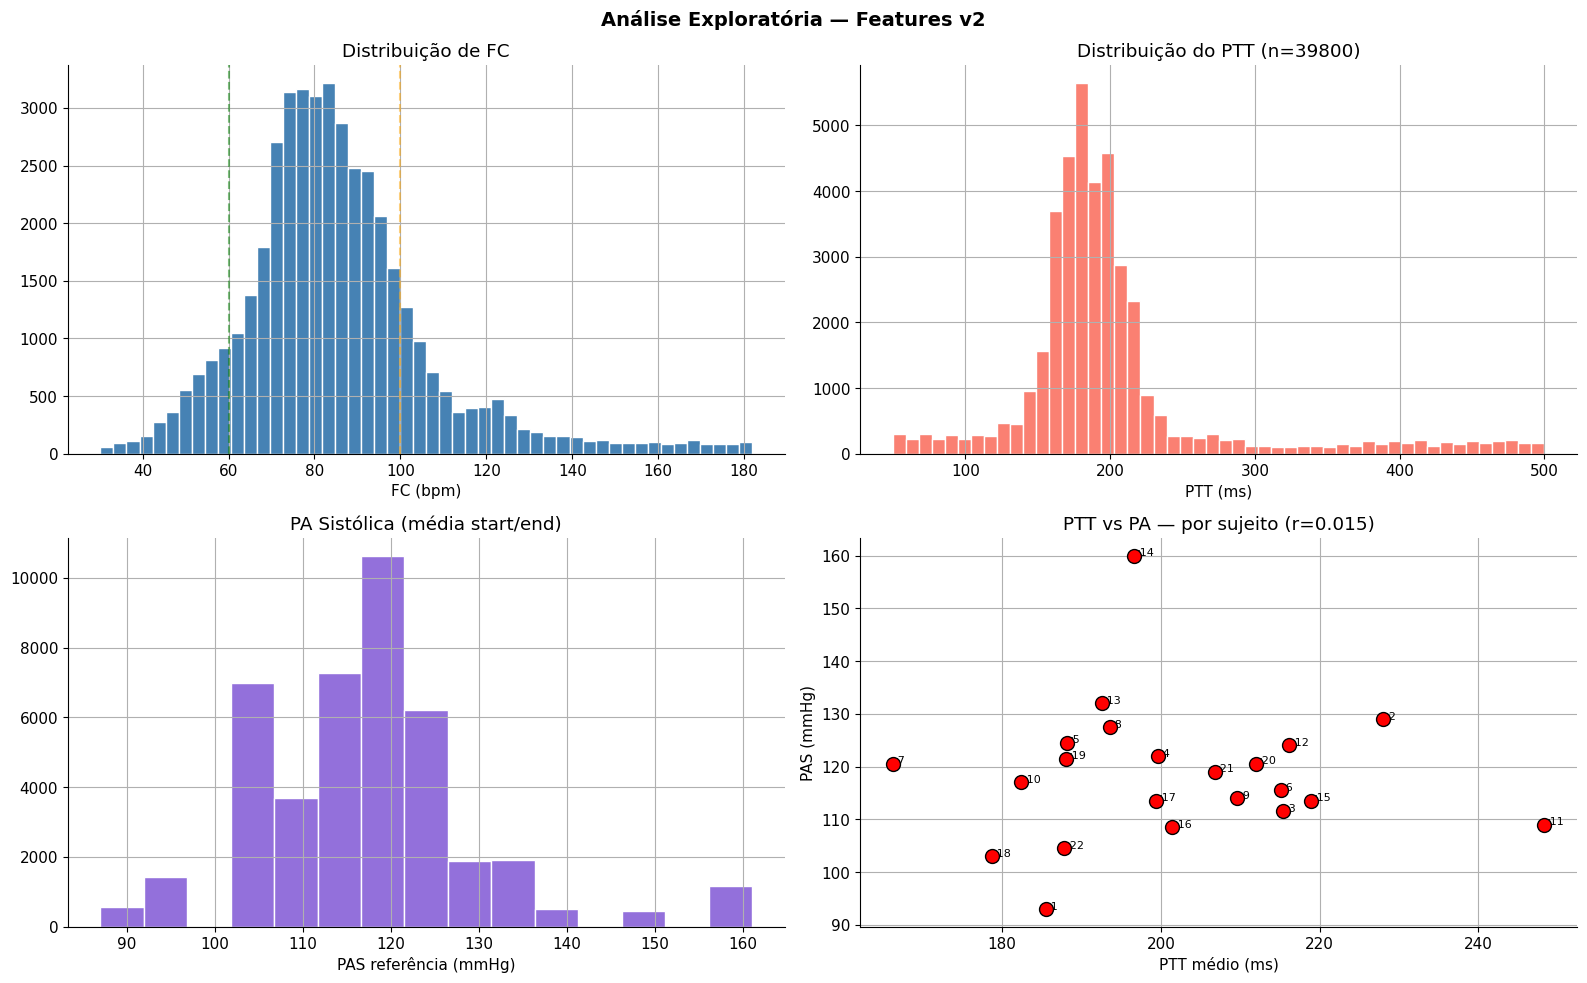

In [30]:
if len(df_all) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    # FC
    axes[0,0].hist(df_all['heart_rate_bpm'], bins=50, color='steelblue', edgecolor='white')
    axes[0,0].set_xlabel('FC (bpm)')
    axes[0,0].set_title('Distribuição de FC')
    axes[0,0].axvline(60, color='green', ls='--', alpha=0.5)
    axes[0,0].axvline(100, color='orange', ls='--', alpha=0.5)
    
    # PTT
    ptt_valid = df_all['ptt_ms'].dropna()
    if len(ptt_valid) > 0:
        axes[0,1].hist(ptt_valid, bins=50, color='salmon', edgecolor='white')
        axes[0,1].set_xlabel('PTT (ms)')
        axes[0,1].set_title(f'Distribuição do PTT (n={len(ptt_valid)})')
    else:
        axes[0,1].text(0.5, 0.5, 'Sem dados de PTT', ha='center', va='center', transform=axes[0,1].transAxes)
    
    # PA sistólica
    bp_vals = df_all['bp_sys_mean'].dropna()
    if len(bp_vals) > 0:
        axes[1,0].hist(bp_vals, bins=15, color='mediumpurple', edgecolor='white')
        axes[1,0].set_xlabel('PAS referência (mmHg)')
        axes[1,0].set_title('PA Sistólica (média start/end)')
    
    # PTT vs PA
    if len(ptt_valid) > 0:
        df_ptt = df_all[df_all['ptt_ms'].notna()]
        ptt_by_subj = df_ptt.groupby('subject').agg(
            ptt_mean=('ptt_ms', 'mean'),
            bp_sys=('bp_sys_mean', 'first')
        ).dropna()
        
        if len(ptt_by_subj) > 2:
            axes[1,1].scatter(ptt_by_subj['ptt_mean'], ptt_by_subj['bp_sys'], 
                              s=100, c='red', edgecolor='black', zorder=5)
            for subj, row in ptt_by_subj.iterrows():
                axes[1,1].annotate(subj, (row['ptt_mean'], row['bp_sys']), fontsize=8)
            axes[1,1].set_xlabel('PTT médio (ms)')
            axes[1,1].set_ylabel('PAS (mmHg)')
            r = np.corrcoef(ptt_by_subj['ptt_mean'], ptt_by_subj['bp_sys'])[0,1]
            axes[1,1].set_title(f'PTT vs PA — por sujeito (r={r:.3f})')
    
    plt.suptitle('Análise Exploratória — Features v2', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ DataFrame vazio — sem gráficos para exibir")


In [31]:
# Top correlações com PA
if len(df_all) > 0 and 'bp_sys_mean' in df_all.columns:
    feat_cols = [c for c in df_all.columns if c not in [
        'record', 'subject', 'condition', 'cycle_idx', 'peak_sample', 'time_s',
        'bp_sys_start', 'bp_sys_end', 'bp_dia_start', 'bp_dia_end',
        'bp_sys_mean', 'bp_dia_mean', 'age', 'gender', 'height', 'weight'
    ] and df_all[c].dtype in ['float64', 'int64', 'Float64']]
    
    corr = df_all[feat_cols + ['bp_sys_mean']].corr()['bp_sys_mean'].drop('bp_sys_mean')
    corr = corr.dropna().sort_values()
    
    print("=" * 60)
    print("TOP CORRELAÇÕES features × PAS")
    print("=" * 60)
    print("\nPositivas (maiores):")
    for feat, val in corr.tail(7).items():
        print(f"   {feat:35s}  r = {val:+.4f}")
    print("\nNegativas (maiores em módulo):")
    for feat, val in corr.head(7).items():
        print(f"   {feat:35s}  r = {val:+.4f}")
    print(f"\nMaior |r|: {corr.abs().max():.4f} ({corr.abs().idxmax()})")
else:
    print("⚠️ Sem dados para calcular correlações")


TOP CORRELAÇÕES features × PAS

Positivas (maiores):
   cardiac_period_s                     r = +0.0696
   w66_ratio                            r = +0.0710
   w33_ratio                            r = +0.0716
   w25_ratio                            r = +0.0721
   w50_ratio                            r = +0.0722
   w10_ratio                            r = +0.0738
   auc                                  r = +0.1392

Negativas (maiores em módulo):
   crest_factor                         r = -0.1265
   skewness                             r = -0.1257
   w75_total                            r = -0.0425
   valley_value                         r = -0.0412
   w75_sys                              r = -0.0276
   w66_sys                              r = -0.0239
   w66_total                            r = -0.0204

Maior |r|: 0.1392 (auc)


BLOXPLOT

Registros por condição: sit=22, walk=22, run=22
PA sistólica geral: 87–161 mmHg (média=117.3 ± 13.2)

✅ Figura salva: figura_boxplot_PA_sistolica.png


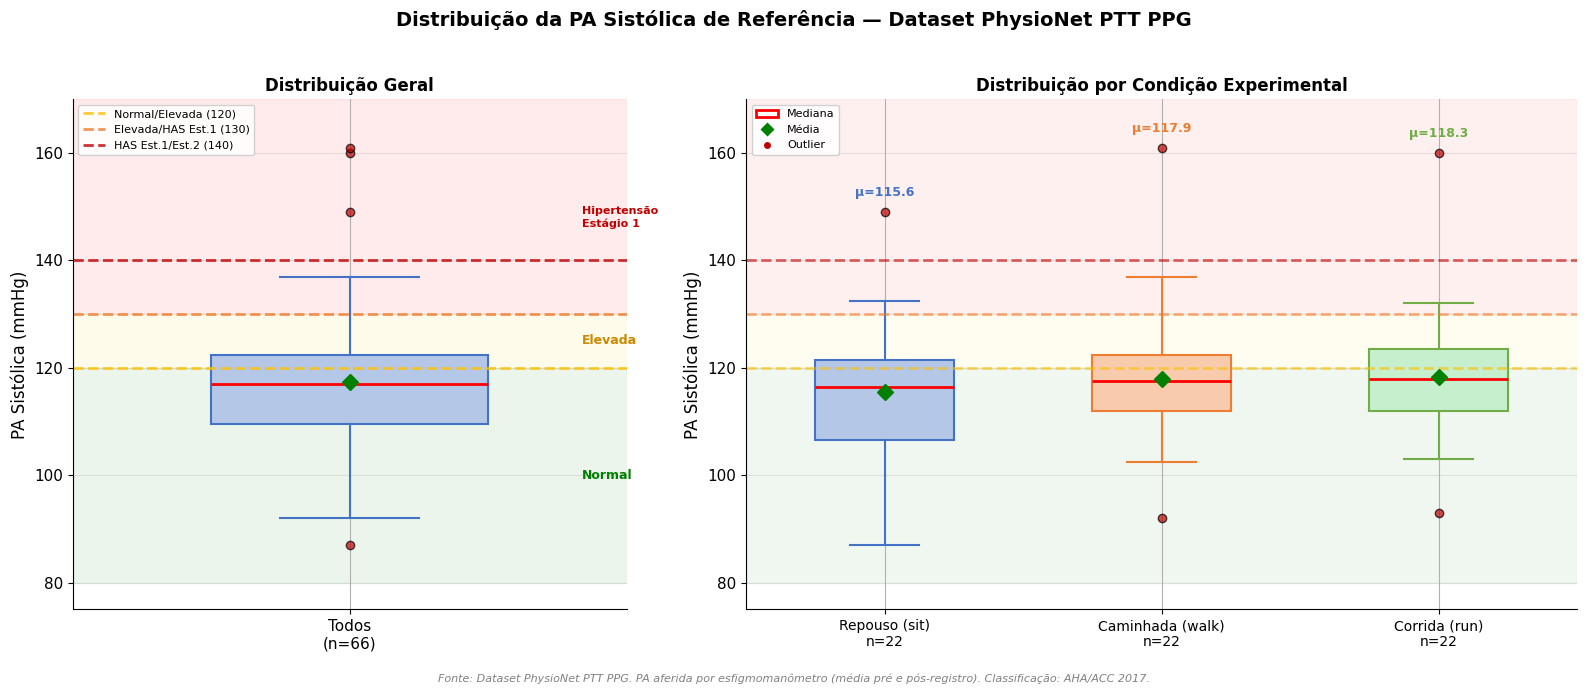

In [32]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ---- 1. PREPARAR OS DADOS ----
# Pegar apenas 1 valor de PA por sujeito × condição (evita repetir 2000x por ciclo)
# groupby pega a primeira ocorrência de cada combinação sujeito + condição
bp_por_registro = df_all.groupby(['subject', 'condition'])['bp_sys_mean'].first().reset_index()

# Separar por condição experimental
bp_sit  = bp_por_registro[bp_por_registro['condition'] == 'sit']['bp_sys_mean'].dropna()
bp_walk = bp_por_registro[bp_por_registro['condition'] == 'walk']['bp_sys_mean'].dropna()
bp_run  = bp_por_registro[bp_por_registro['condition'] == 'run']['bp_sys_mean'].dropna()

# Todos os valores juntos (para o boxplot geral)
bp_todos = bp_por_registro['bp_sys_mean'].dropna()

print(f"Registros por condição: sit={len(bp_sit)}, walk={len(bp_walk)}, run={len(bp_run)}")
print(f"PA sistólica geral: {bp_todos.min():.0f}–{bp_todos.max():.0f} mmHg "
      f"(média={bp_todos.mean():.1f} ± {bp_todos.std():.1f})")

# ---- 2. CRIAR A FIGURA ----
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.5]})
fig.suptitle('Distribuição da PA Sistólica de Referência — Dataset PhysioNet PTT PPG',
             fontsize=14, fontweight='bold', y=0.97)

# ---- PAINEL ESQUERDO: Boxplot geral (todos os registros) ----
ax1 = axes[0]

bp1 = ax1.boxplot(
    [bp_todos],
    positions=[1],
    widths=0.5,
    patch_artist=True,          # Permite colorir a caixa
    showmeans=True,             # Mostra a média (triângulo verde)
    meanprops=dict(marker='D', markerfacecolor='green', markeredgecolor='green', markersize=8),
    medianprops=dict(color='red', linewidth=2),
    boxprops=dict(facecolor='#B4C7E7', edgecolor='#4472C4', linewidth=1.5),
    whiskerprops=dict(color='#4472C4', linewidth=1.5),
    capprops=dict(color='#4472C4', linewidth=1.5),
    flierprops=dict(marker='o', markerfacecolor='#C00000', markersize=6, alpha=0.7)
)

# Linhas de corte clínicas (classificação de PA segundo diretrizes)
ax1.axhline(y=120, color='#FFC000', linewidth=2, linestyle='--', alpha=0.8, label='Normal/Elevada (120)')
ax1.axhline(y=130, color='#ED7D31', linewidth=2, linestyle='--', alpha=0.8, label='Elevada/HAS Est.1 (130)')
ax1.axhline(y=140, color='#C00000', linewidth=2, linestyle='--', alpha=0.8, label='HAS Est.1/Est.2 (140)')

# Faixas de classificação coloridas (fundo)
ax1.axhspan(80,  120, alpha=0.08, color='green')    # Normal
ax1.axhspan(120, 130, alpha=0.08, color='gold')     # Elevada
ax1.axhspan(130, 170, alpha=0.08, color='red')      # Hipertensão

# Anotações das faixas
ax1.text(1.42, 100, 'Normal', fontsize=9, color='green', fontweight='bold', va='center')
ax1.text(1.42, 125, 'Elevada', fontsize=9, color='#CC8800', fontweight='bold', va='center')
ax1.text(1.42, 148, 'Hipertensão\nEstágio 1', fontsize=8, color='#C00000', fontweight='bold', 
         va='center', linespacing=1.3)

ax1.set_ylabel('PA Sistólica (mmHg)', fontsize=12)
ax1.set_xticks([1])
ax1.set_xticklabels(['Todos\n(n=66)'], fontsize=11)
ax1.set_ylim(75, 170)
ax1.set_title('Distribuição Geral', fontsize=12, fontweight='bold')
ax1.legend(loc='upper left', fontsize=8, framealpha=0.9)
ax1.grid(axis='y', alpha=0.3)

# ---- PAINEL DIREITO: Boxplot por condição (sit, walk, run) ----
ax2 = axes[1]

dados_condicao = [bp_sit, bp_walk, bp_run]
cores_caixa = ['#B4C7E7', '#F8CBAD', '#C6EFCE']    # Azul claro, laranja claro, verde claro
cores_borda = ['#4472C4', '#ED7D31', '#70AD47']     # Azul, laranja, verde
labels_cond = [
    f'Repouso (sit)\nn={len(bp_sit)}',
    f'Caminhada (walk)\nn={len(bp_walk)}',
    f'Corrida (run)\nn={len(bp_run)}'
]

bp2 = ax2.boxplot(
    dados_condicao,
    positions=[1, 2, 3],
    widths=0.5,
    patch_artist=True,
    showmeans=True,
    meanprops=dict(marker='D', markerfacecolor='green', markeredgecolor='green', markersize=8),
    medianprops=dict(color='red', linewidth=2),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(marker='o', markerfacecolor='#C00000', markersize=6, alpha=0.7)
)

# Colorir cada caixa individualmente
for i, (box, cor_f, cor_b) in enumerate(zip(bp2['boxes'], cores_caixa, cores_borda)):
    box.set_facecolor(cor_f)
    box.set_edgecolor(cor_b)
    box.set_linewidth(1.5)
    # Colorir whiskers e caps também
    bp2['whiskers'][i*2].set_color(cor_b)
    bp2['whiskers'][i*2+1].set_color(cor_b)
    bp2['caps'][i*2].set_color(cor_b)
    bp2['caps'][i*2+1].set_color(cor_b)

# Mesmas linhas de corte clínicas
ax2.axhline(y=120, color='#FFC000', linewidth=2, linestyle='--', alpha=0.6)
ax2.axhline(y=130, color='#ED7D31', linewidth=2, linestyle='--', alpha=0.6)
ax2.axhline(y=140, color='#C00000', linewidth=2, linestyle='--', alpha=0.6)

# Faixas coloridas de fundo
ax2.axhspan(80,  120, alpha=0.06, color='green')
ax2.axhspan(120, 130, alpha=0.06, color='gold')
ax2.axhspan(130, 170, alpha=0.06, color='red')

# Anotar média de cada condição acima da caixa
for i, dados in enumerate(dados_condicao):
    media = dados.mean()
    ax2.text(i+1, dados.max() + 3, f'μ={media:.1f}',
             ha='center', fontsize=9, fontweight='bold', color=cores_borda[i])

ax2.set_ylabel('PA Sistólica (mmHg)', fontsize=12)
ax2.set_xticks([1, 2, 3])
ax2.set_xticklabels(labels_cond, fontsize=10)
ax2.set_ylim(75, 170)
ax2.set_title('Distribuição por Condição Experimental', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# ---- LEGENDA explicativa ----
legenda_items = [
    mpatches.Patch(facecolor='white', edgecolor='red', linewidth=2, label='Mediana'),
    plt.Line2D([0],[0], marker='D', color='w', markerfacecolor='green', markersize=8, label='Média'),
    plt.Line2D([0],[0], marker='o', color='w', markerfacecolor='#C00000', markersize=6, label='Outlier'),
]
ax2.legend(handles=legenda_items, loc='upper left', fontsize=8, framealpha=0.9)

# ---- RODAPÉ ----
fig.text(0.5, 0.01,
    'Fonte: Dataset PhysioNet PTT PPG. PA aferida por esfigmomanômetro (média pré e pós-registro). '
    'Classificação: AHA/ACC 2017.',
    ha='center', fontsize=8, color='gray', style='italic')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])

# ---- 3. SALVAR ----
plt.savefig('figura_boxplot_PA_sistolica.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print("\n✅ Figura salva: figura_boxplot_PA_sistolica.png")

plt.show()

✅ Figura salva: figura_ppg_3_etapas.png


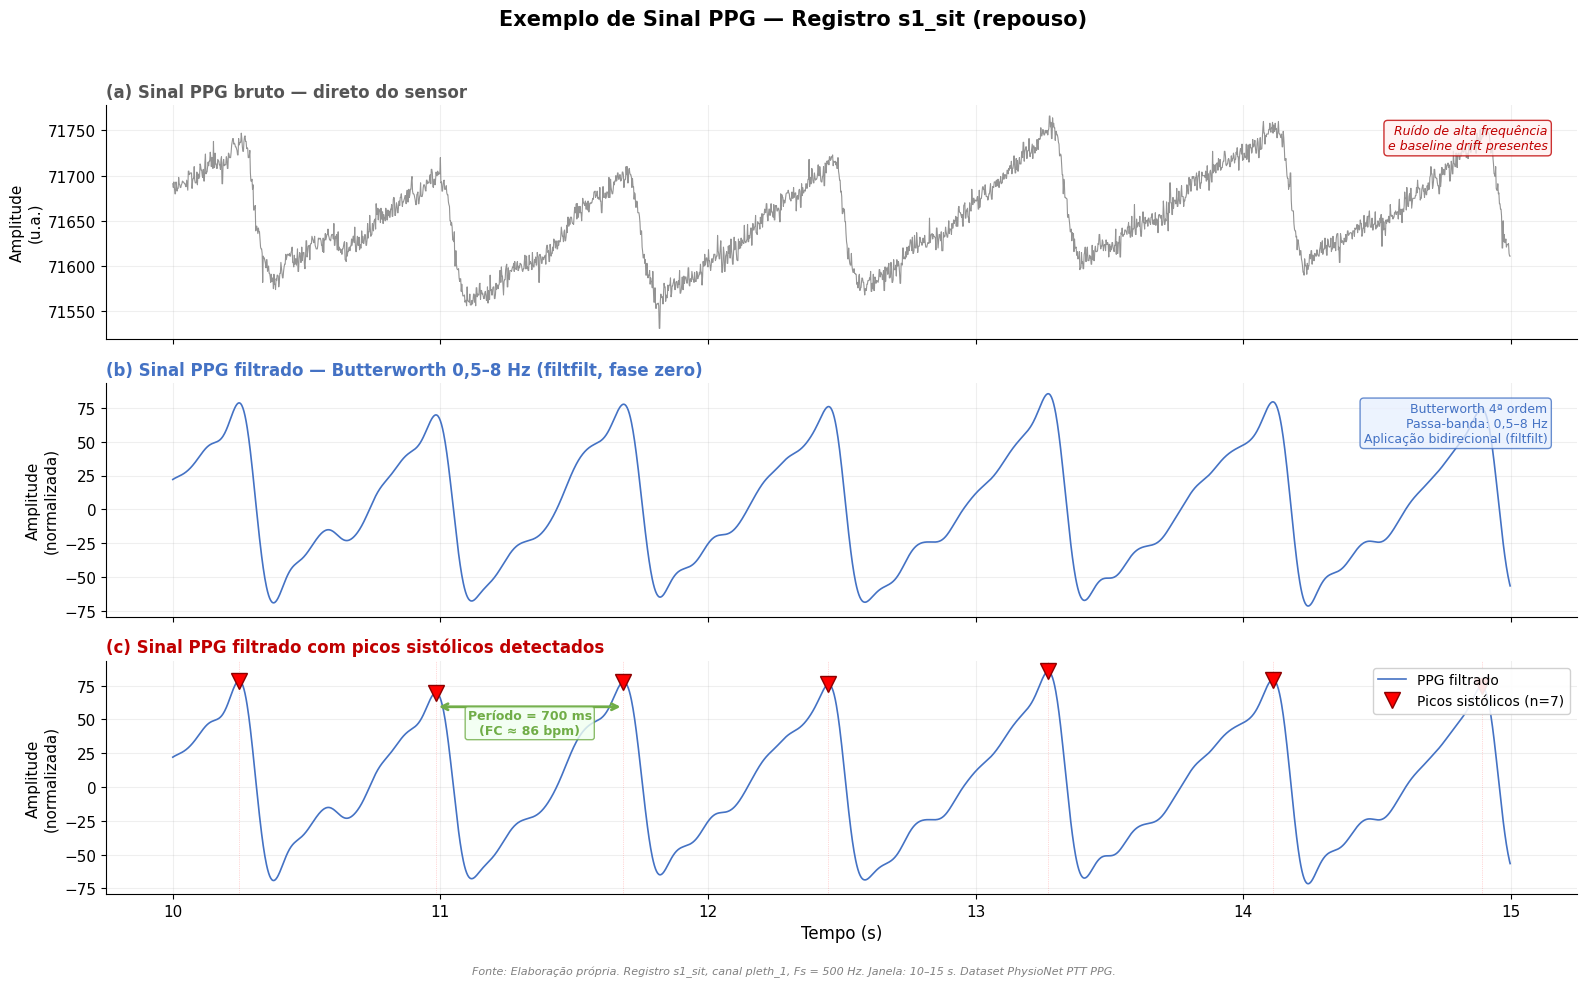

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# ---- 1. DEFINIR JANELA DE TEMPO ----
# Vamos mostrar 5 segundos de sinal (de 10s a 15s do registro)
# Esse trecho já foi usado nas células anteriores, então é consistente
t_inicio = 10   # segundo inicial
t_fim    = 15   # segundo final
s = int(t_inicio * fs)   # amostra inicial (10 * 500 = 5000)
e = int(t_fim * fs)      # amostra final   (15 * 500 = 7500)
time = np.arange(s, e) / fs   # vetor de tempo em segundos

# ---- 2. EXTRAIR OS 3 SINAIS ----
# (a) Sinal bruto — direto do sensor, sem nenhum processamento
sinal_bruto = ppg_raw[s:e]

# (b) Sinal filtrado — após Butterworth 0,5–8 Hz (bidirecional, fase zero)
sinal_filtrado = ppg_filt[s:e]

# (c) Picos sistólicos — dentro da janela de tempo selecionada
picos_na_janela = peaks_ppg[(peaks_ppg >= s) & (peaks_ppg < e)]

# ---- 3. CRIAR A FIGURA COM 3 PAINÉIS ----
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
fig.suptitle('Exemplo de Sinal PPG — Registro s1_sit (repouso)',
             fontsize=15, fontweight='bold', y=0.97)

# ---- Painel (a): SINAL BRUTO ----
ax_a = axes[0]
ax_a.plot(time, sinal_bruto, color='#888888', linewidth=0.8, alpha=0.9)
ax_a.set_ylabel('Amplitude\n(u.a.)', fontsize=11)
ax_a.set_title('(a) Sinal PPG bruto — direto do sensor',
               loc='left', fontsize=12, fontweight='bold', color='#555555')
ax_a.grid(axis='both', alpha=0.2)

# Destaque: região com ruído de alta frequência
ax_a.text(0.98, 0.92, 'Ruído de alta frequência\ne baseline drift presentes',
          transform=ax_a.transAxes, ha='right', va='top',
          fontsize=9, color='#C00000', style='italic',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF0F0', edgecolor='#C00000', alpha=0.8))

# ---- Painel (b): SINAL FILTRADO ----
ax_b = axes[1]
ax_b.plot(time, sinal_filtrado, color='#4472C4', linewidth=1.2)
ax_b.set_ylabel('Amplitude\n(normalizada)', fontsize=11)
ax_b.set_title('(b) Sinal PPG filtrado — Butterworth 0,5–8 Hz (filtfilt, fase zero)',
               loc='left', fontsize=12, fontweight='bold', color='#4472C4')
ax_b.grid(axis='both', alpha=0.2)

# Anotação do filtro
ax_b.text(0.98, 0.92, 'Butterworth 4ª ordem\nPassa-banda: 0,5–8 Hz\nAplicação bidirecional (filtfilt)',
          transform=ax_b.transAxes, ha='right', va='top',
          fontsize=9, color='#4472C4',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='#E8F0FE', edgecolor='#4472C4', alpha=0.8))

# ---- Painel (c): FILTRADO + PICOS DETECTADOS ----
ax_c = axes[2]
ax_c.plot(time, sinal_filtrado, color='#4472C4', linewidth=1.2, label='PPG filtrado')

# Marcar os picos sistólicos com triângulos vermelhos
ax_c.plot(picos_na_janela / fs, ppg_filt[picos_na_janela],
          'rv', markersize=12, markeredgecolor='darkred', markeredgewidth=1,
          label=f'Picos sistólicos (n={len(picos_na_janela)})', zorder=5)

# Linhas verticais tracejadas nos picos (para visualizar melhor)
for pk in picos_na_janela:
    ax_c.axvline(x=pk/fs, color='red', linewidth=0.5, alpha=0.3, linestyle=':')

ax_c.set_ylabel('Amplitude\n(normalizada)', fontsize=11)
ax_c.set_xlabel('Tempo (s)', fontsize=12)
ax_c.set_title('(c) Sinal PPG filtrado com picos sistólicos detectados',
               loc='left', fontsize=12, fontweight='bold', color='#C00000')
ax_c.legend(loc='upper right', fontsize=10, framealpha=0.9)
ax_c.grid(axis='both', alpha=0.2)

# Anotar intervalo entre picos (período cardíaco)
if len(picos_na_janela) >= 2:
    # Mostrar o intervalo entre o 2º e 3º pico como exemplo
    pk1 = picos_na_janela[1]
    pk2 = picos_na_janela[2]
    t1 = pk1 / fs
    t2 = pk2 / fs
    intervalo = (pk2 - pk1) / fs
    fc_local = 60 / intervalo

    # Seta bidirecional entre os dois picos
    y_seta = ppg_filt[pk1] * 0.85
    ax_c.annotate('', xy=(t2, y_seta), xytext=(t1, y_seta),
                  arrowprops=dict(arrowstyle='<->', color='#70AD47', linewidth=2))
    ax_c.text((t1 + t2) / 2, y_seta * 0.97,
              f'Período = {intervalo*1000:.0f} ms\n(FC ≈ {fc_local:.0f} bpm)',
              ha='center', va='top', fontsize=9, fontweight='bold', color='#70AD47',
              bbox=dict(boxstyle='round,pad=0.2', facecolor='#F0FFF0', edgecolor='#70AD47', alpha=0.8))

# ---- RODAPÉ ----
fig.text(0.5, 0.005,
    'Fonte: Elaboração própria. Registro s1_sit, canal pleth_1, Fs = 500 Hz. '
    'Janela: 10–15 s. Dataset PhysioNet PTT PPG.',
    ha='center', fontsize=8, color='gray', style='italic')

plt.tight_layout(rect=[0, 0.02, 1, 0.95])

# ---- 4. SALVAR ----
plt.savefig('figura_ppg_3_etapas.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print("✅ Figura salva: figura_ppg_3_etapas.png")

plt.show()


✅ Figura salva: figura_top15_correlacoes.png


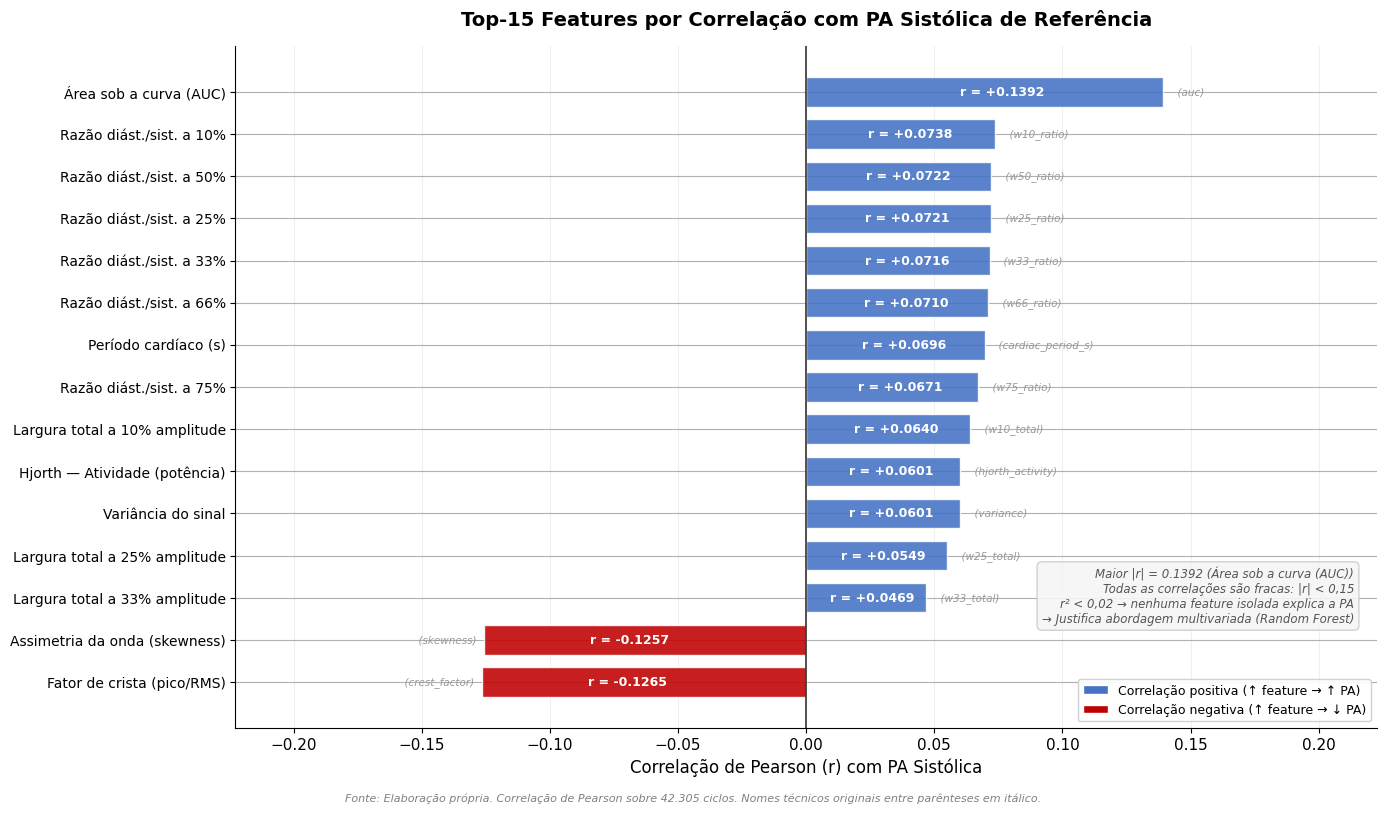

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# ---- 1. DICIONÁRIO DE NOMES DESCRITIVOS ----
# Traduz o nome técnico da feature para uma descrição clara em português
nomes_descritivos = {
    # TEMPORAIS
    'cardiac_period_s':         'Período cardíaco (s)',
    'heart_rate_bpm':           'Frequência cardíaca (bpm)',
    'systolic_upstroke_time_s': 'Tempo de subida sistólica (s)',
    'diastolic_time_s':         'Tempo diastólico (s)',
    'sut_dt_ratio':             'Razão sístole/diástole',
    # LARGURAS (6 percentuais × 4 variantes = 24)
    'w10_total':  'Largura total a 10% amplitude',
    'w10_sys':    'Largura sistólica a 10%',
    'w10_dia':    'Largura diastólica a 10%',
    'w10_ratio':  'Razão diást./sist. a 10%',
    'w25_total':  'Largura total a 25% amplitude',
    'w25_sys':    'Largura sistólica a 25%',
    'w25_dia':    'Largura diastólica a 25%',
    'w25_ratio':  'Razão diást./sist. a 25%',
    'w33_total':  'Largura total a 33% amplitude',
    'w33_sys':    'Largura sistólica a 33%',
    'w33_dia':    'Largura diastólica a 33%',
    'w33_ratio':  'Razão diást./sist. a 33%',
    'w50_total':  'Largura total a 50% amplitude',
    'w50_sys':    'Largura sistólica a 50%',
    'w50_dia':    'Largura diastólica a 50%',
    'w50_ratio':  'Razão diást./sist. a 50%',
    'w66_total':  'Largura total a 66% amplitude',
    'w66_sys':    'Largura sistólica a 66%',
    'w66_dia':    'Largura diastólica a 66%',
    'w66_ratio':  'Razão diást./sist. a 66%',
    'w75_total':  'Largura total a 75% amplitude',
    'w75_sys':    'Largura sistólica a 75%',
    'w75_dia':    'Largura diastólica a 75%',
    'w75_ratio':  'Razão diást./sist. a 75%',
    # AMPLITUDE
    'amplitude':    'Amplitude pico-vale',
    'peak_value':   'Valor absoluto do pico',
    'valley_value': 'Valor absoluto do vale',
    'crest_factor': 'Fator de crista (pico/RMS)',
    # ESTATÍSTICAS
    'variance':  'Variância do sinal',
    'std':       'Desvio padrão do sinal',
    'skewness':  'Assimetria da onda (skewness)',
    'kurtosis':  'Curtose da onda (kurtosis)',
    'auc':       'Área sob a curva (AUC)',
    # HJORTH
    'hjorth_activity':   'Hjorth — Atividade (potência)',
    'hjorth_mobility':   'Hjorth — Mobilidade (freq. média)',
    'hjorth_complexity': 'Hjorth — Complexidade (largura banda)',
    # PTT
    'ptt_s':  'PTT — Tempo de trânsito do pulso (s)',
    'ptt_ms': 'PTT — Tempo de trânsito do pulso (ms)',
}

def traduzir_feature(nome_tecnico):
    """Retorna o nome descritivo. Se não encontrar, retorna o original."""
    return nomes_descritivos.get(nome_tecnico, nome_tecnico)

# ---- 2. SELECIONAR TOP-15 POR |r| ----
top15 = corr.abs().sort_values(ascending=False).head(15)
top15_com_sinal = corr[top15.index].sort_values(ascending=True)

# Traduzir nomes
nomes_traduzidos = [traduzir_feature(f) for f in top15_com_sinal.index]
valores = top15_com_sinal.values

# ---- 3. CORES ----
cores = ['#4472C4' if v > 0 else '#C00000' for v in valores]

# ---- 4. CRIAR O GRÁFICO ----
fig, ax = plt.subplots(figsize=(14, 8))

y_pos = np.arange(len(nomes_traduzidos))

barras = ax.barh(y_pos, valores, color=cores, edgecolor='white', height=0.7, alpha=0.88)

# ---- 5. VALOR DE r + NOME TÉCNICO DENTRO DE CADA BARRA ----
for i, (barra, val, nome_orig) in enumerate(zip(barras, valores, top15_com_sinal.index)):
    if abs(val) > 0.04:
        x_texto = val * 0.55
        cor_texto = 'white'
    else:
        x_texto = val + (0.008 if val > 0 else -0.008)
        cor_texto = '#333333'

    ax.text(x_texto, i, f'r = {val:+.4f}',
            ha='center', va='center', fontsize=9, fontweight='bold', color=cor_texto)

    # Nome técnico original em cinza ao lado da barra
    x_label = val + (0.003 if val > 0 else -0.003)
    ha_label = 'left' if val > 0 else 'right'
    ax.text(x_label, i, f'  ({nome_orig})',
            ha=ha_label, va='center', fontsize=7.5, color='#999999', style='italic')

# ---- 6. FORMATAR ----
ax.set_yticks(y_pos)
ax.set_yticklabels(nomes_traduzidos, fontsize=10)
ax.set_xlabel('Correlação de Pearson (r) com PA Sistólica', fontsize=12)
ax.set_title('Top-15 Features por Correlação com PA Sistólica de Referência',
             fontsize=14, fontweight='bold', pad=15)

ax.axvline(x=0, color='#333333', linewidth=1.2)

x_max = max(abs(valores.min()), abs(valores.max())) * 1.6
ax.set_xlim(-x_max, x_max)

ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

# ---- 7. LEGENDA ----
legenda = [
    Patch(facecolor='#4472C4', edgecolor='white', label='Correlação positiva (↑ feature → ↑ PA)'),
    Patch(facecolor='#C00000', edgecolor='white', label='Correlação negativa (↑ feature → ↓ PA)'),
]
ax.legend(handles=legenda, loc='lower right', fontsize=9, framealpha=0.9)

# ---- 8. CAIXA INTERPRETATIVA ----
ax.text(0.98, 0.15,
    f'Maior |r| = {corr.abs().max():.4f} ({traduzir_feature(corr.abs().idxmax())})\n'
    f'Todas as correlações são fracas: |r| < 0,15\n'
    f'r² < 0,02 → nenhuma feature isolada explica a PA\n'
    f'→ Justifica abordagem multivariada (Random Forest)',
    transform=ax.transAxes, ha='right', va='bottom',
    fontsize=8.5, color='#555555', style='italic',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#F5F5F5', edgecolor='#CCCCCC', alpha=0.9))

# ---- RODAPÉ ----
fig.text(0.5, -0.01,
    'Fonte: Elaboração própria. Correlação de Pearson sobre 42.305 ciclos. '
    'Nomes técnicos originais entre parênteses em itálico.',
    ha='center', fontsize=8, color='gray', style='italic')

plt.tight_layout()

# ---- 9. SALVAR ----
plt.savefig('figura_top15_correlacoes.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print("✅ Figura salva: figura_top15_correlacoes.png")

plt.show()


## 17. Salvar Features para Modelagem

In [35]:
if len(df_all) > 0:
    # Salvar completo
    output_path = os.path.join(BASE_PATH, '_features_v2_all.csv')
    df_all.to_csv(output_path, index=False)
    print(f"✅ Features v2 salvas: {output_path}")
    print(f"   Shape: {df_all.shape}")
    
    # Versão limpa
    df_clean = df_all[(df_all['heart_rate_bpm'] >= 40) & (df_all['heart_rate_bpm'] <= 180)].copy()
    initial = len(df_all)
    
    clean_path = os.path.join(BASE_PATH, '_features_v2_clean.csv')
    df_clean.to_csv(clean_path, index=False)
    
    print(f"\n✅ Features limpas salvas: {clean_path}")
    print(f"   Shape: {df_clean.shape}")
    print(f"   Ciclos removidos: {initial - len(df_clean)} ({(initial-len(df_clean))/initial*100:.1f}%)")
    print(f"   Sujeitos: {df_clean['subject'].nunique()}")
    print(f"   Registros: {df_clean['record'].nunique()}")
    print(f"   Ciclos com PTT: {df_clean['ptt_s'].notna().sum()}")
else:
    print("⚠️ Sem dados para salvar")


✅ Features v2 salvas: C:\Users\USER B. Godoi\.openclaw\workspace\datasets\PTT_PPG\_features_v2_all.csv
   Shape: (42659, 59)

✅ Features limpas salvas: C:\Users\USER B. Godoi\.openclaw\workspace\datasets\PTT_PPG\_features_v2_clean.csv
   Shape: (42305, 59)
   Ciclos removidos: 354 (0.8%)
   Sujeitos: 22
   Registros: 66
   Ciclos com PTT: 39507


Dados para PCA: 3233 ciclos × 43 features

Resultados do PCA:
  Total de componentes: 43
  Componentes para 90% da variância: 8
  Componentes para 95% da variância: 11
  Variância do PC1: 33.6%
  Variância do PC2: 21.6%
  Variância PC1+PC2: 55.3%

✅ Figura 8 salva: figura8_pca_variancia.png


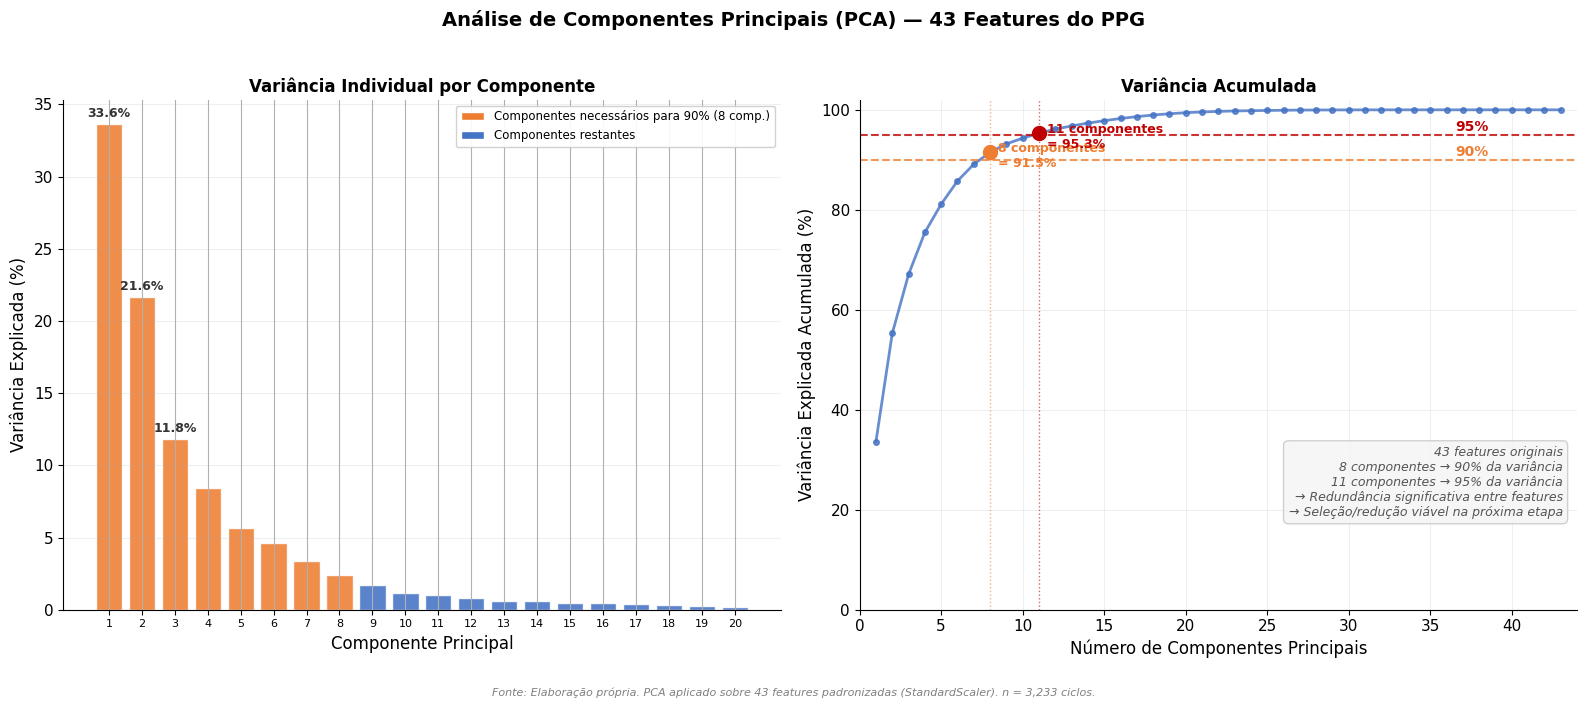

In [36]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---- 1. PREPARAR DADOS ----
# Pegar apenas as colunas de features
feat_cols = [c for c in df_all.columns if c not in [
    'record', 'subject', 'condition', 'cycle_idx', 'peak_sample', 'time_s',
    'bp_sys_start', 'bp_sys_end', 'bp_dia_start', 'bp_dia_end',
    'bp_sys_mean', 'bp_dia_mean', 'age', 'gender', 'height', 'weight'
] and df_all[c].dtype in ['float64', 'int64', 'Float64']]

# Remover linhas com NaN nas features
X_pca = df_all[feat_cols].dropna()
print(f"Dados para PCA: {X_pca.shape[0]} ciclos × {X_pca.shape[1]} features")

# Padronizar (PCA é sensível à escala)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

# ---- 2. APLICAR PCA ----
pca = PCA()
pca.fit(X_scaled)

# Resultados
var_individual = pca.explained_variance_ratio_       # variância de cada componente
var_acumulada  = np.cumsum(var_individual)            # variância acumulada
n_componentes  = len(var_individual)

# Quantos componentes para 90% e 95%?
n_90 = np.argmax(var_acumulada >= 0.90) + 1
n_95 = np.argmax(var_acumulada >= 0.95) + 1

print(f"\nResultados do PCA:")
print(f"  Total de componentes: {n_componentes}")
print(f"  Componentes para 90% da variância: {n_90}")
print(f"  Componentes para 95% da variância: {n_95}")
print(f"  Variância do PC1: {var_individual[0]*100:.1f}%")
print(f"  Variância do PC2: {var_individual[1]*100:.1f}%")
print(f"  Variância PC1+PC2: {var_acumulada[1]*100:.1f}%")

# ---- 3. CRIAR FIGURA COM 2 PAINÉIS ----
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Análise de Componentes Principais (PCA) — 43 Features do PPG',
             fontsize=14, fontweight='bold', y=0.97)

# ---- PAINEL ESQUERDO: Variância individual por componente (barras) ----
ax1 = axes[0]

# Mostrar os primeiros 20 componentes (os demais são muito pequenos)
n_mostrar = min(20, n_componentes)
x_bars = np.arange(1, n_mostrar + 1)

cores_barras = ['#ED7D31' if i < n_90 else '#4472C4' for i in range(n_mostrar)]

ax1.bar(x_bars, var_individual[:n_mostrar] * 100, color=cores_barras,
        edgecolor='white', alpha=0.88)

ax1.set_xlabel('Componente Principal', fontsize=12)
ax1.set_ylabel('Variância Explicada (%)', fontsize=12)
ax1.set_title('Variância Individual por Componente', fontsize=12, fontweight='bold')
ax1.set_xticks(x_bars)
ax1.set_xticklabels(x_bars, fontsize=8)
ax1.grid(axis='y', alpha=0.2)

# Anotar os 3 primeiros
for i in range(min(3, n_mostrar)):
    ax1.text(i + 1, var_individual[i] * 100 + 0.5,
             f'{var_individual[i]*100:.1f}%',
             ha='center', fontsize=9, fontweight='bold', color='#333333')

from matplotlib.patches import Patch
leg1 = [
    Patch(facecolor='#ED7D31', edgecolor='white',
          label=f'Componentes necessários para 90% ({n_90} comp.)'),
    Patch(facecolor='#4472C4', edgecolor='white',
          label='Componentes restantes'),
]
ax1.legend(handles=leg1, loc='upper right', fontsize=8.5, framealpha=0.9)

# ---- PAINEL DIREITO: Variância acumulada (linha) ----
ax2 = axes[1]

ax2.plot(range(1, n_componentes + 1), var_acumulada * 100,
         'o-', color='#4472C4', linewidth=2, markersize=4, alpha=0.8)

# Linha horizontal em 90%
ax2.axhline(y=90, color='#ED7D31', linewidth=1.5, linestyle='--', alpha=0.8)
ax2.text(n_componentes * 0.85, 90.8, '90%', fontsize=10, color='#ED7D31', fontweight='bold')

# Linha horizontal em 95%
ax2.axhline(y=95, color='#C00000', linewidth=1.5, linestyle='--', alpha=0.8)
ax2.text(n_componentes * 0.85, 95.8, '95%', fontsize=10, color='#C00000', fontweight='bold')

# Marcador vertical no ponto de 90%
ax2.axvline(x=n_90, color='#ED7D31', linewidth=1, linestyle=':', alpha=0.6)
ax2.plot(n_90, var_acumulada[n_90-1] * 100, 'o', color='#ED7D31', markersize=10, zorder=5)
ax2.text(n_90 + 0.5, var_acumulada[n_90-1] * 100 - 3,
         f'{n_90} componentes\n= {var_acumulada[n_90-1]*100:.1f}%',
         fontsize=9, fontweight='bold', color='#ED7D31')

# Marcador vertical no ponto de 95%
ax2.axvline(x=n_95, color='#C00000', linewidth=1, linestyle=':', alpha=0.6)
ax2.plot(n_95, var_acumulada[n_95-1] * 100, 'o', color='#C00000', markersize=10, zorder=5)
ax2.text(n_95 + 0.5, var_acumulada[n_95-1] * 100 - 3,
         f'{n_95} componentes\n= {var_acumulada[n_95-1]*100:.1f}%',
         fontsize=9, fontweight='bold', color='#C00000')

ax2.set_xlabel('Número de Componentes Principais', fontsize=12)
ax2.set_ylabel('Variância Explicada Acumulada (%)', fontsize=12)
ax2.set_title('Variância Acumulada', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 102)
ax2.set_xlim(0, n_componentes + 1)
ax2.grid(alpha=0.2)

# Caixa interpretativa
ax2.text(0.98, 0.25,
    f'43 features originais\n'
    f'{n_90} componentes → 90% da variância\n'
    f'{n_95} componentes → 95% da variância\n'
    f'→ Redundância significativa entre features\n'
    f'→ Seleção/redução viável na próxima etapa',
    transform=ax2.transAxes, ha='right', va='center',
    fontsize=9, color='#555555', style='italic',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='#F5F5F5',
              edgecolor='#CCCCCC', alpha=0.9))

# ---- RODAPÉ ----
fig.text(0.5, -0.01,
    'Fonte: Elaboração própria. PCA aplicado sobre 43 features padronizadas (StandardScaler). '
    f'n = {X_pca.shape[0]:,} ciclos.',
    ha='center', fontsize=8, color='gray', style='italic')

plt.tight_layout(rect=[0, 0.02, 1, 0.95])

# ---- 4. SALVAR ----
plt.savefig('figura8_pca_variancia.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
print("\n✅ Figura 8 salva: figura8_pca_variancia.png")

plt.show()